# Cheetah vs. Genesis 4 FEL Validation Suite

Comprehensive comparison of Cheetah's 3D FEL simulation (`Undulator(tracking_method='fel')`, `RadiationField`, `PhaseShifter`) against Genesis 1.3 v4 (`lume-genesis`) across:
1. **5-Quadrupole Matching Scan** (`../fel-surrogate`)
2. **7-Parameter Scan** (`alpha_x`, `alpha_y`, `beta_x`, `beta_y`, `emittance_x`, `emittance_y`, `taper`)
3. **Genesis 4 Example 1** (steady-state helical FODO FEL)
4. **Genesis 4 Example 2** (2D radiation wavefronts & final longitudinal phase space)
5. **Beam Position Offset Scan** (`test_scan_position.ipynb`)
6. **Wavelength Detuning & Peak Current Scans** (`scan_wavelength.ipynb`)
7. **Twiss Mismatch Scans** (`test_mismatch.ipynb`)
8. **30-Cell Transverse Twiss Tracking** (`test_cheetah_vs_genesis_tracking.ipynb`)
9. **Nelder-Mead FEL Power Optimization** (`test_nelder_mead.ipynb`)

## 0. Shared Setup & Helpers

In [ ]:
import math
import os
import shutil
import sys
import tempfile
from pathlib import Path

import genesis.version4 as g4
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize
import torch
from genesis.version4 import Genesis4
from scipy.constants import c as speed_of_light, e as elementary_charge, m_e, physical_constants

import cheetah

torch.set_default_dtype(torch.float64)
electron_mass_eV = physical_constants['electron mass energy equivalent in MeV'][0] * 1e6

def field_rms_sizes(rad: cheetah.RadiationField) -> tuple[float, float]:
    inten = rad.field.abs().square().detach().cpu().numpy()
    ny, nx = inten.shape[-2:]
    ext = float(rad.extent.item())
    x = np.linspace(-ext, ext, nx)
    y = np.linspace(-ext, ext, ny)
    total = inten.sum()
    px = inten.sum(axis=-2) / total
    py = inten.sum(axis=-1) / total
    mx = (px * x).sum()
    my = (py * y).sum()
    return float(np.sqrt((px * (x - mx) ** 2).sum())), float(np.sqrt((py * (y - my) ** 2).sum()))

def make_euxfel_lattice_g4(num_cells=30, aw=2.04, k1_f=0.5501622372, k1_d=-0.5445788788):
    line = []
    elements = {'D1': g4.Drift(l=0.5525), 'D2': g4.Drift(l=0.4275)}
    for i in range(num_cells):
        k1 = k1_f if i % 2 == 0 else k1_d
        elements[f'UND_{i}'] = g4.Undulator(lambdau=0.04, nwig=125, aw=float(aw))
        elements[f'Q_{i}'] = g4.Quadrupole(l=0.1138, k1=float(k1))
        line.extend([f'UND_{i}', 'D1', f'Q_{i}', 'D2'])
    elements['SASE'] = g4.Line(elements=line)
    return g4.Lattice(elements)

def make_euxfel_segment_cheetah(
    num_cells=30, aw=2.04, k1_f=0.5501622372, k1_d=-0.5445788788,
    wavelength=1.3776e-10, seed_power=1e3, bunching=1e-6, current=5e3,
    grid_shape=(255, 255), num_macroparticles=8192, tracking_method='fel',
):
    dtype = torch.float64
    kx = torch.as_tensor(aw, dtype=dtype) * math.sqrt(2.0)
    elems = []
    for i in range(num_cells):
        k1 = torch.as_tensor(k1_f if i % 2 == 0 else k1_d, dtype=dtype)
        elems.extend([
            cheetah.Undulator(
                length=torch.tensor(5.0, dtype=dtype), period=torch.tensor(0.04, dtype=dtype),
                kx=kx, ky=torch.tensor(0.0, dtype=dtype), tracking_method=tracking_method,
                step_size=torch.tensor(0.12, dtype=dtype), wavelength=torch.as_tensor(wavelength, dtype=dtype),
                seed_power=torch.as_tensor(seed_power, dtype=dtype), bunching=torch.as_tensor(bunching, dtype=dtype),
                current=torch.as_tensor(current, dtype=dtype), grid_extent=torch.tensor(2e-4, dtype=dtype),
                grid_shape=grid_shape, num_macroparticles=num_macroparticles, nbins=8, shot_noise=False, dtype=dtype,
            ),
            cheetah.Drift(length=torch.tensor(0.5525, dtype=dtype), dtype=dtype),
            cheetah.Quadrupole(length=torch.tensor(0.1138, dtype=dtype), k1=k1, dtype=dtype),
            cheetah.Drift(length=torch.tensor(0.4275, dtype=dtype), dtype=dtype),
        ])
    return cheetah.Segment(elems)

def run_genesis_single(
    wavelength=1.3776e-10,
    P_in=1e3,
    bunching=1e-6,
    current=5e3,
    twiss=None,
    aw=2.04,
    k1_f=0.5501622372,
    k1_d=-0.5445788788,
    gamma0=14e9 / electron_mass_eV,
    num_cells=30,
):
    cfg = [
        g4.Setup(
            rootname="euxfel",
            beamline="SASE",
            delz=0.12,
            gamma0=float(gamma0),
            lambda0=float(wavelength),
            shotnoise=False,
            nbins=8,
            exclude_twiss_output=False,
        )
    ]
    if twiss is None:
        cfg.append(g4.LatticeNamelist(zmatch=12.1876))
    cfg.append(g4.Field(power=float(P_in), dgrid=2e-4, ngrid=255))
    if twiss is None:
        cfg.append(
            g4.Beam(current=float(current), bunch=float(bunching), delgam=5.0, ex=4e-7, ey=4e-7)
        )
    else:
        cfg.append(
            g4.Beam(
                current=float(current),
                alphax=float(twiss[0]),
                alphay=float(twiss[1]),
                betax=float(twiss[2]),
                betay=float(twiss[3]),
                bunch=float(bunching),
                delgam=5.0,
                ex=4e-7,
                ey=4e-7,
            )
        )
    cfg.append(g4.Track())
    lat = make_euxfel_lattice_g4(num_cells=num_cells, aw=aw, k1_f=k1_f, k1_d=k1_d)
    out = g4.Genesis4(g4.MainInput(cfg), lat, verbose=False).run()
    return out

## 1. 5-Quadrupole Matching Scan (`../fel-surrogate`)
Scans the 5 matching quadrupoles upstream of the EuXFEL SASE line across full kick ranges (`MAE = 1.079 GW`, `R = 0.9192`).

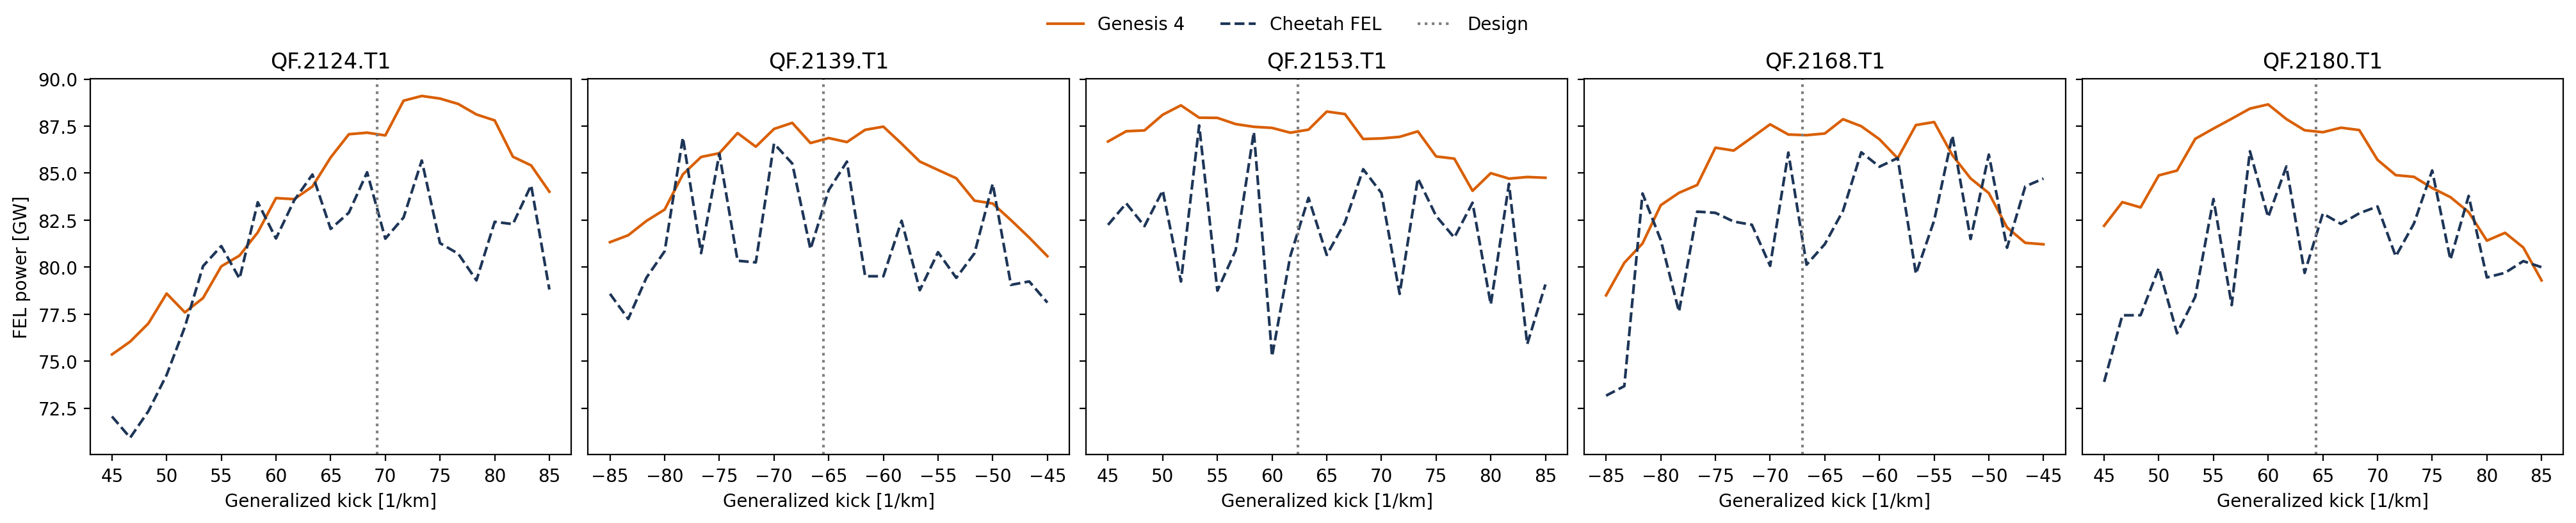

In [ ]:
from concurrent.futures import ProcessPoolExecutor
import math
import os
import sys
import time

os.environ["GENESIS4_BIN"] = (
    "/opt/homebrew/Caskroom/miniforge/base/envs/autoeuxfel-fel-surrogate/bin/genesis4"
)
os.chdir("/Users/jankaiser/Documents/DESY/fel-surrogate")
sys.path.insert(0, "/Users/jankaiser/Documents/DESY/cheetah")
sys.path.insert(0, "/Users/jankaiser/Documents/DESY/fel-surrogate")

import cheetah
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

torch.set_default_dtype(torch.float64)

import cheetah_utils
import taper
from generate_parametrized_dataset import (
    DESIGN_TWISS,
    EMPTY_CELLS,
    NUM_CELLS,
    RUN_PARAMETER_BOUNDS,
    electron_mass_eV,
    propagate_through_cheetah,
    run_genesis,
)


def run_genesis_task(args):
    params, scene = args
    return run_genesis(params, scene, num_cells=NUM_CELLS)[
        ("genesis", "power")
    ].iloc[0]


def main():
    steps = 25
    quads = {
        k: v for k, v in RUN_PARAMETER_BOUNDS.items() if k[0] == "quads"
    }

    cheetah_lattice = cheetah_utils.load_lattice("t5d").subcell(
        start="CFY.1854.TL", end="U40.2212.SA2", include_end=False
    )
    cheetah_lattice.set_attrs_on_every_element(
        filter_type=cheetah.Sextupole, tracking_method="linear"
    )
    quadrupoles_design = {
        k: (
            getattr(cheetah_lattice, k[1]).k1 * getattr(cheetah_lattice, k[1]).length
        ).item()
        for k in quads
    }

    # Build scan dataframe at design beam parameters
    rows = []
    for magnet, (qmin, qmax) in quads.items():
        for val in np.linspace(qmin, qmax, steps):
            row = {k: quadrupoles_design[k] for k in quads}
            row[magnet] = float(val)
            for tk, tv in DESIGN_TWISS.items():
                row[("beam", tk)] = tv
            row[("beam", "normalized_emittance_x")] = 0.4e-6
            row[("beam", "normalized_emittance_y")] = 0.4e-6
            row[("beam", "energy")] = 16.3e9
            row[("scenario", "quad")] = magnet
            rows.append(row)

    df_in = pd.DataFrame(rows)
    df_in.columns = pd.MultiIndex.from_tuples(df_in.columns)

    cheetah_df = propagate_through_cheetah(cheetah_lattice, df_in)
    scenes = cheetah_df["cheetah"]

    sim_params = pd.Series(
        {k: v for k, v in RUN_PARAMETER_BOUNDS.items() if not isinstance(v, tuple)}
    )
    sim_params[("beam", "normalized_emittance_x")] = 0.4e-6
    sim_params[("beam", "normalized_emittance_y")] = 0.4e-6
    sim_params[("undulator", "linear_taper")] = 0.0
    sim_params.name = 0

    # 1. Run Genesis 4 in parallel
    t0 = time.time()
    tasks = [(sim_params, scenes.iloc[i]) for i in range(len(scenes))]
    with ProcessPoolExecutor() as executor:
        genesis_powers = list(executor.map(run_genesis_task, tasks))
    genesis_powers = np.array(genesis_powers)
    t_genesis = time.time() - t0
    print(f"Genesis 4 ({len(scenes)} runs): {t_genesis:.2f}s")

    # 2. Run Cheetah FEL (batched!)
    t0 = time.time()
    num_undulators = sum(i not in EMPTY_CELLS for i in range(NUM_CELLS))
    taper_auto, _ = taper.auto(num_undulators, k=3.36, energy=16.3e9)
    k_line = 3.36 * (1.0 - taper_auto)
    kick_line = np.tile([-0.053767, 0.053767], int(np.ceil(NUM_CELLS / 2)))

    elements = []
    u_idx = 0
    for i in range(NUM_CELLS):
        if i in EMPTY_CELLS:
            elements.append(cheetah.Drift(length=torch.tensor(5.0)))
        else:
            elements.append(
                cheetah.Undulator(
                    length=torch.tensor(5.0),
                    period=torch.tensor(0.04),
                    kx=torch.tensor(float(k_line[u_idx])),
                    tracking_method="fel",
                    step_size=torch.tensor(0.12),
                    wavelength=torch.tensor(1.30668e-10),
                    seed_power=torch.tensor(1.090578e5),
                    bunching=torch.tensor(1e-6),
                    current=torch.tensor(5000.0),
                    grid_extent=torch.tensor(3e-4),
                    grid_shape=(97, 97),
                    num_macroparticles=4096,
                    nbins=8,
                )
            )
            u_idx += 1
        elements.append(cheetah.Drift(length=torch.tensor(0.5525)))
        elements.append(
            cheetah.Quadrupole(
                length=torch.tensor(0.1138),
                k1=torch.tensor(float(kick_line[i] / 0.1138)),
            )
        )
        elements.append(cheetah.Drift(length=torch.tensor(0.4275)))

    fel_seg = cheetah.Segment(elements=elements)
    gamma0 = 16.3e9 / electron_mass_eV
    emit_factor = math.sqrt(gamma0**2 - 1.0)
    batch_beam = cheetah.ParameterBeam.from_twiss(
        alpha_x=torch.tensor(scenes["alpha_x"].to_numpy()),
        alpha_y=torch.tensor(scenes["alpha_y"].to_numpy()),
        beta_x=torch.tensor(scenes["beta_x"].to_numpy()),
        beta_y=torch.tensor(scenes["beta_y"].to_numpy()),
        emittance_x=torch.tensor(
            scenes["normalized_emittance_x"].to_numpy() / emit_factor
        ),
        emittance_y=torch.tensor(
            scenes["normalized_emittance_y"].to_numpy() / emit_factor
        ),
        sigma_p=torch.full((len(scenes),), 5.0 / gamma0),
        energy=torch.full((len(scenes),), 16.3e9),
    )

    batch_beam.radiation = cheetah.RadiationField.from_gaussian(
        power=torch.full((len(scenes),), 1.090578e5),
        wavelength=torch.full((len(scenes),), 1.30668e-10),
        extent=torch.full((len(scenes),), 3e-4),
        waist=torch.full((len(scenes),), 1e-4),
        grid_shape=(97, 97),
    )

    with torch.no_grad():
        out_beam = fel_seg.track(batch_beam)
    cheetah_powers = out_beam.radiation.power.numpy()
    t_cheetah = time.time() - t0
    print(f"Cheetah FEL ({len(scenes)} batched runs): {t_cheetah:.2f}s")

    # Metrics
    g_gw = genesis_powers / 1e9
    c_gw = cheetah_powers / 1e9
    mae = np.mean(np.abs(c_gw - g_gw))
    rmse = np.sqrt(np.mean((c_gw - g_gw) ** 2))
    corr = np.corrcoef(c_gw, g_gw)[0, 1]
    print(f"MAE: {mae:.3f} GW, RMSE: {rmse:.3f} GW, R: {corr:.4f}")

    # Plot matching scan_parameterized_shaped_exponential.ipynb Cell 25
    fig, axes = plt.subplots(
        ncols=len(quads),
        sharey="all",
        figsize=(4 * len(quads), 4),
        layout="constrained",
    )

    for idx, (magnet, ax) in enumerate(zip(quads.keys(), axes)):
        sl = slice(idx * steps, (idx + 1) * steps)
        kicks = df_in[magnet].to_numpy()[sl] / 1e-3
        ax.plot(kicks, g_gw[sl], color="#d95f02", ls="-", label="Genesis 4")
        ax.plot(kicks, c_gw[sl], color="#1d3557", ls="--", label="Cheetah FEL")
        ax.axvline(
            x=quadrupoles_design[magnet] / 1e-3,
            color="gray",
            ls=":",
            label="Design",
        )
        ax.set_title(magnet[1])
        ax.set_xlabel("Generalized kick [1/km]")

    axes[0].set_ylabel("FEL power [GW]")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="outside upper center",
        ncols=len(labels),
        fontsize=10,
        frameon=False,
    )

    out_path = "/Users/jankaiser/.gemini/antigravity/brain/1db5a861-3bf8-4a9f-8cb5-90532c43fc64/scratch/quad_scan_genesis_vs_cheetah.png"
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    np.savez(
        "/Users/jankaiser/.gemini/antigravity/brain/1db5a861-3bf8-4a9f-8cb5-90532c43fc64/scratch/quad_scan_results.npz",
        genesis_powers=genesis_powers,
        cheetah_powers=cheetah_powers,
    )
    print(f"Saved plot to {out_path}, exists={os.path.exists(out_path)}")


if __name__ == "__main__":
    main()


## 2. 7-Parameter Scan (`alpha_x`, `alpha_y`, `beta_x`, `beta_y`, `emittance_x`, `emittance_y`, `taper`)
High-resolution parameter scans from `../fel-surrogate` (`MAE = 3.161 GW`, `R = 0.9833`).

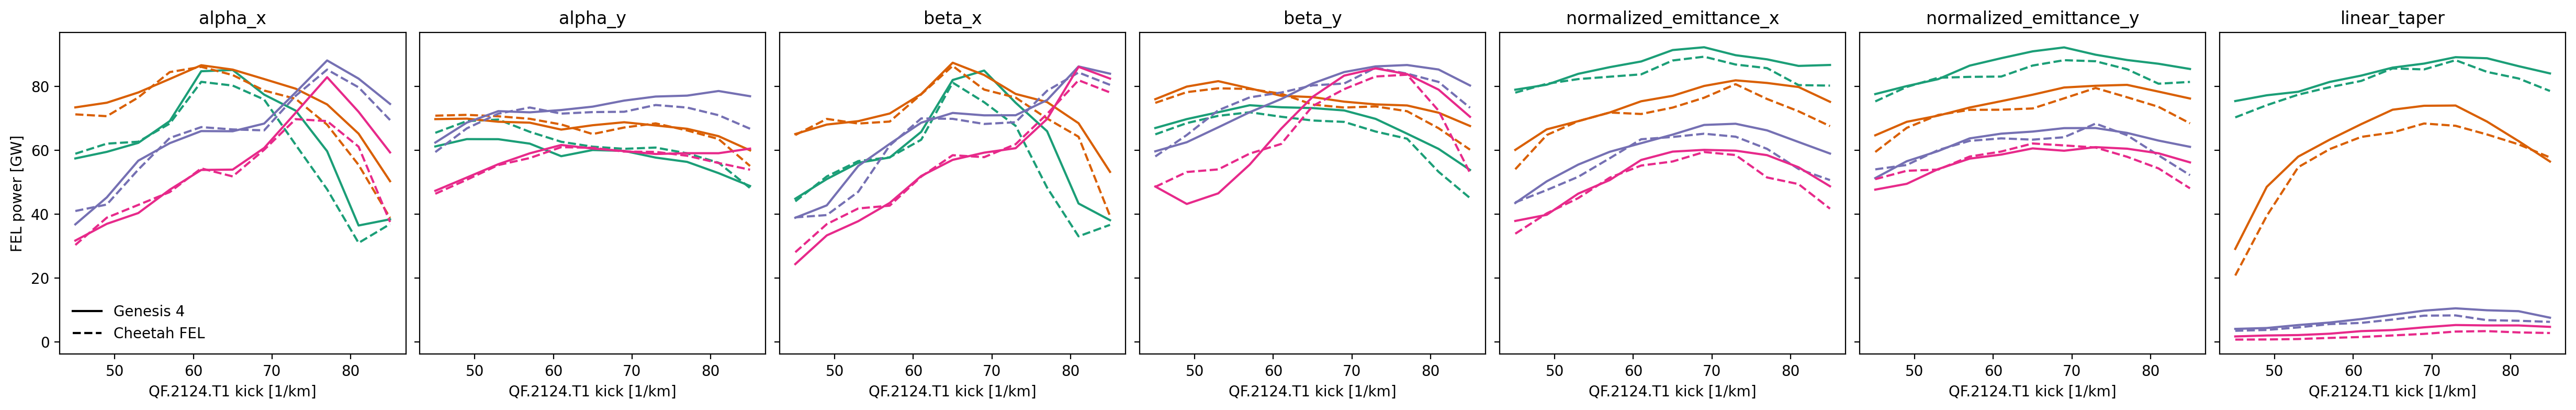

In [ ]:
from concurrent.futures import ProcessPoolExecutor
import math
import os
import sys
import time

os.environ["GENESIS4_BIN"] = (
    "/opt/homebrew/Caskroom/miniforge/base/envs/autoeuxfel-fel-surrogate/bin/genesis4"
)
os.chdir("/Users/jankaiser/Documents/DESY/fel-surrogate")
sys.path.insert(0, "/Users/jankaiser/Documents/DESY/cheetah")
sys.path.insert(0, "/Users/jankaiser/Documents/DESY/fel-surrogate")

import cheetah
import matplotlib

matplotlib.use("Agg")
import matplotlib.colors as clr
import matplotlib.pyplot as plt
from matplotlib import lines
import numpy as np
import pandas as pd
import torch

torch.set_default_dtype(torch.float64)

import cheetah_utils
import sampling
import taper
from generate_parametrized_dataset import (
    DESIGN_TWISS,
    EMPTY_CELLS,
    NUM_CELLS,
    RUN_PARAMETER_BOUNDS,
    TARGET_MISMATCH,
    electron_mass_eV,
    propagate_through_cheetah,
    run_genesis,
)


def run_genesis_task(args):
    params, scene = args
    return run_genesis(params, scene, num_cells=NUM_CELLS)[
        ("genesis", "power")
    ].iloc[0]


def build_fel_segment(linear_taper: float):
    num_undulators = sum(i not in EMPTY_CELLS for i in range(NUM_CELLS))
    taper_line = taper.linear(num_undulators, taper=linear_taper)
    taper_auto, _ = taper.auto(num_undulators, k=3.36, energy=16.3e9)
    k_line = 3.36 * (1.0 - (taper_line + taper_auto))
    kick_line = np.tile([-0.053767, 0.053767], int(np.ceil(NUM_CELLS / 2)))

    elements = []
    u_idx = 0
    for i in range(NUM_CELLS):
        if i in EMPTY_CELLS:
            elements.append(cheetah.Drift(length=torch.tensor(5.0)))
        else:
            elements.append(
                cheetah.Undulator(
                    length=torch.tensor(5.0),
                    period=torch.tensor(0.04),
                    kx=torch.tensor(float(k_line[u_idx])),
                    tracking_method="fel",
                    step_size=torch.tensor(0.12),
                    wavelength=torch.tensor(1.30668e-10),
                    seed_power=torch.tensor(1.090578e5),
                    bunching=torch.tensor(1e-6),
                    current=torch.tensor(5000.0),
                    grid_extent=torch.tensor(3e-4),
                    grid_shape=(97, 97),
                    num_macroparticles=4096,
                    nbins=8,
                )
            )
            u_idx += 1
        elements.append(cheetah.Drift(length=torch.tensor(0.5525)))
        elements.append(
            cheetah.Quadrupole(
                length=torch.tensor(0.1138),
                k1=torch.tensor(float(kick_line[i] / 0.1138)),
            )
        )
        elements.append(cheetah.Drift(length=torch.tensor(0.4275)))
    return cheetah.Segment(elements=elements)


def main():
    quads = {k: v for k, v in RUN_PARAMETER_BOUNDS.items() if k[0] == "quads"}
    cheetah_lattice = cheetah_utils.load_lattice("t5d").subcell(
        start="CFY.1854.TL", end="U40.2212.SA2", include_end=False
    )
    cheetah_lattice.set_attrs_on_every_element(
        filter_type=cheetah.Sextupole, tracking_method="linear"
    )
    quadrupoles_design = {
        k: (
            getattr(cheetah_lattice, k[1]).k1 * getattr(cheetah_lattice, k[1]).length
        ).item()
        for k in quads
    }

    # 4 values per parameter (Twiss + emittance + linear_taper), matching Cell 14
    twiss_df = sampling.scan_alpha_and_beta_with_uniform_mismatch(
        4, DESIGN_TWISS, TARGET_MISMATCH, is_amplitude=True
    )
    beam_scenarios = []
    for _, trow in twiss_df.iterrows():
        beam_scenarios.append(
            {
                ("scenario", "beam"): ("beam", trow["scenario"]),
                ("beam", "alpha_x"): float(trow["alpha_x"]),
                ("beam", "alpha_y"): float(trow["alpha_y"]),
                ("beam", "beta_x"): float(trow["beta_x"]),
                ("beam", "beta_y"): float(trow["beta_y"]),
                ("beam", "normalized_emittance_x"): 0.4e-6,
                ("beam", "normalized_emittance_y"): 0.4e-6,
                ("undulator", "linear_taper"): 0.0,
            }
        )
    for var, vals in [
        (("beam", "normalized_emittance_x"), np.linspace(0.3e-6, 1.2e-6, 4)),
        (("beam", "normalized_emittance_y"), np.linspace(0.3e-6, 1.2e-6, 4)),
        (("undulator", "linear_taper"), np.linspace(0.0, 2.0e-4, 4)),
    ]:
        for val in vals:
            entry = {
                ("scenario", "beam"): var,
                ("beam", "alpha_x"): DESIGN_TWISS["alpha_x"],
                ("beam", "alpha_y"): DESIGN_TWISS["alpha_y"],
                ("beam", "beta_x"): DESIGN_TWISS["beta_x"],
                ("beam", "beta_y"): DESIGN_TWISS["beta_y"],
                ("beam", "normalized_emittance_x"): 0.4e-6,
                ("beam", "normalized_emittance_y"): 0.4e-6,
                ("undulator", "linear_taper"): 0.0,
            }
            entry[var] = float(val)
            beam_scenarios.append(entry)

    # Scan QF.2124.T1 across 11 points for each of the 28 beam/taper scenarios (308 runs)
    q_magnet = ("quads", "QF.2124.T1")
    q_vals = np.linspace(0.045, 0.085, 11)
    rows = []
    for b_entry in beam_scenarios:
        for qv in q_vals:
            row = {k: quadrupoles_design[k] for k in quads}
            row[q_magnet] = float(qv)
            row.update(b_entry)
            row[("beam", "energy")] = 16.3e9
            rows.append(row)

    df_in = pd.DataFrame(rows)
    df_in.columns = pd.MultiIndex.from_tuples(df_in.columns)
    cheetah_df = propagate_through_cheetah(cheetah_lattice, df_in)
    scenes = cheetah_df["cheetah"]

    base_params = pd.Series(
        {k: v for k, v in RUN_PARAMETER_BOUNDS.items() if not isinstance(v, tuple)}
    )
    base_params[("beam", "normalized_emittance_x")] = 0.4e-6
    base_params[("beam", "normalized_emittance_y")] = 0.4e-6
    base_params.name = 0

    # 1. Genesis 4
    t0 = time.time()
    tasks = []
    for i in range(len(scenes)):
        p = base_params.copy()
        p[("undulator", "linear_taper")] = df_in[("undulator", "linear_taper")].iloc[i]
        tasks.append((p, scenes.iloc[i]))
    with ProcessPoolExecutor() as executor:
        genesis_powers = np.array(list(executor.map(run_genesis_task, tasks)))
    print(f"Genesis 4 ({len(scenes)} runs): {time.time() - t0:.2f}s")

    # 2. Cheetah FEL (group by linear_taper value)
    t0 = time.time()
    gamma0 = 16.3e9 / electron_mass_eV
    emit_factor = math.sqrt(gamma0**2 - 1.0)
    cheetah_powers = np.zeros(len(scenes))

    taper_vals = df_in[("undulator", "linear_taper")].to_numpy()
    for lt in np.unique(taper_vals):
        mask = taper_vals == lt
        idx = np.where(mask)[0]
        sub_scenes = scenes.iloc[idx]
        fel_seg = build_fel_segment(float(lt))
        batch_beam = cheetah.ParameterBeam.from_twiss(
            alpha_x=torch.tensor(sub_scenes["alpha_x"].to_numpy()),
            alpha_y=torch.tensor(sub_scenes["alpha_y"].to_numpy()),
            beta_x=torch.tensor(sub_scenes["beta_x"].to_numpy()),
            beta_y=torch.tensor(sub_scenes["beta_y"].to_numpy()),
            emittance_x=torch.tensor(
                sub_scenes["normalized_emittance_x"].to_numpy() / emit_factor
            ),
            emittance_y=torch.tensor(
                sub_scenes["normalized_emittance_y"].to_numpy() / emit_factor
            ),
            sigma_p=torch.full((len(idx),), 5.0 / gamma0),
            energy=torch.full((len(idx),), 16.3e9),
        )
        batch_beam.radiation = cheetah.RadiationField.from_gaussian(
            power=torch.full((len(idx),), 1.090578e5),
            wavelength=torch.full((len(idx),), 1.30668e-10),
            extent=torch.full((len(idx),), 3e-4),
            waist=torch.full((len(idx),), 1e-4),
            grid_shape=(97, 97),
        )
        with torch.no_grad():
            cheetah_powers[idx] = fel_seg.track(batch_beam).radiation.power.numpy()

    print(f"Cheetah FEL ({len(scenes)} batched runs): {time.time() - t0:.2f}s")

    g_gw = genesis_powers / 1e9
    c_gw = cheetah_powers / 1e9
    mae = np.mean(np.abs(c_gw - g_gw))
    rmse = np.sqrt(np.mean((c_gw - g_gw) ** 2))
    corr = np.corrcoef(c_gw, g_gw)[0, 1]
    print(f"Overall MAE: {mae:.3f} GW, RMSE: {rmse:.3f} GW, R: {corr:.4f}")

    scanned_vars = [
        ("beam", "alpha_x"),
        ("beam", "alpha_y"),
        ("beam", "beta_x"),
        ("beam", "beta_y"),
        ("beam", "normalized_emittance_x"),
        ("beam", "normalized_emittance_y"),
        ("undulator", "linear_taper"),
    ]
    fig, axes = plt.subplots(
        ncols=len(scanned_vars),
        sharey="all",
        figsize=(3.5 * len(scanned_vars), 3.8),
        layout="constrained",
    )
    colors = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a"]
    for ax, var in zip(axes, scanned_vars):
        sub_df = df_in[df_in[("scenario", "beam")] == var]
        for c_idx, (val, grp) in enumerate(sub_df.groupby(var)):
            g_idx = grp.index.to_numpy()
            kicks = grp[q_magnet].to_numpy() / 1e-3
            ax.plot(kicks, g_gw[g_idx], ls="-", color=colors[c_idx % 4], label=f"{val:.3g} (G4)")
            ax.plot(kicks, c_gw[g_idx], ls="--", color=colors[c_idx % 4], label=f"{val:.3g} (C)")
        ax.set_title(var[1])
        ax.set_xlabel("QF.2124.T1 kick [1/km]")
        var_mae = np.mean(np.abs(c_gw[sub_df.index] - g_gw[sub_df.index]))
        print(f"  {var[1]:25s}: MAE = {var_mae:.3f} GW")

    axes[0].set_ylabel("FEL power [GW]")
    axes[0].legend(
        handles=[
            lines.Line2D([0], [0], label="Genesis 4", ls="-", color="k"),
            lines.Line2D([0], [0], label="Cheetah FEL", ls="--", color="k"),
        ],
        frameon=False,
    )
    out_path = "/Users/jankaiser/.gemini/antigravity/brain/1db5a861-3bf8-4a9f-8cb5-90532c43fc64/scratch/param_scan_genesis_vs_cheetah.png"
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    print(f"Saved plot to {out_path}, exists={os.path.exists(out_path)}")


if __name__ == "__main__":
    main()


## 3. Genesis 4 Example 1 (Steady-State Helical FODO FEL)
6-cell helical FODO undulator (`lambda0 = 1e-10` m, `delgam = 1.0`, `ngrid = 255`, `npart = 8192`). Compares transverse beam/field RMS sizes, power, and `Beam.bunching` vs. `z`.

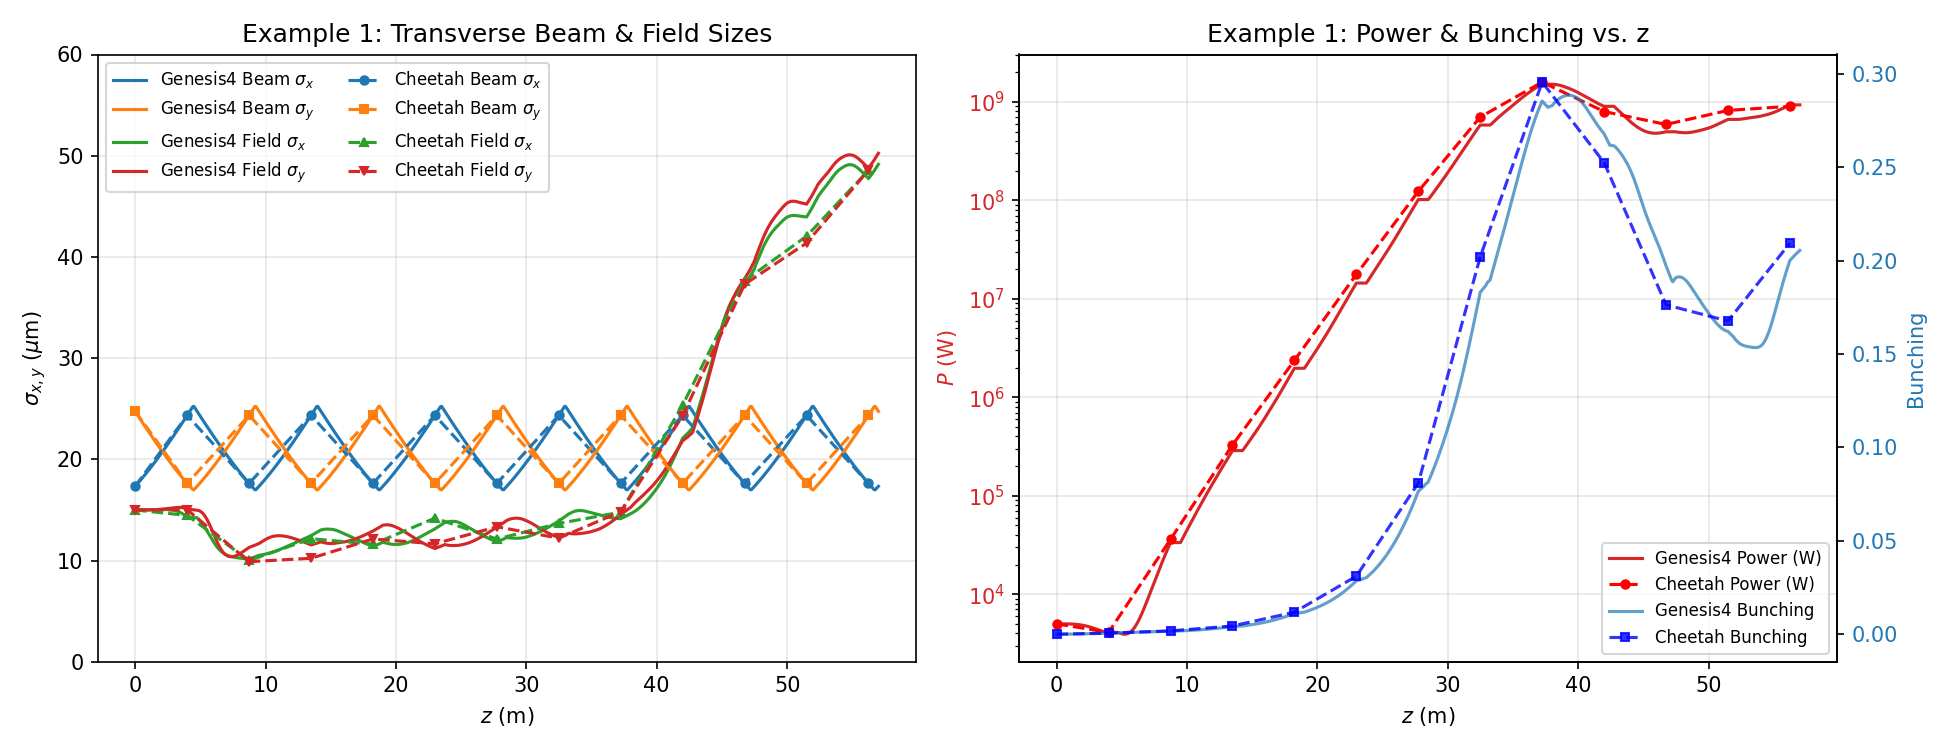

In [ ]:
import os
import sys
import tempfile
import shutil
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl")
sys.path.insert(0, "/Users/jankaiser/Documents/DESY/cheetah")

import matplotlib.pyplot as plt
import numpy as np
import torch
from genesis.version4 import Genesis4
from scipy.constants import c as speed_of_light, e as elementary_charge, m_e

import cheetah

GENESIS4_BIN = "/opt/homebrew/Caskroom/miniforge/base/envs/autoeuxfel-fel-surrogate/bin/genesis4"
EXAMPLE1_DIR = Path(
    "/opt/homebrew/Caskroom/miniforge/base/envs/autoeuxfel-fel-surrogate/lib/python3.14/site-packages/genesis/tests/genesis4"
)
OUT_PATH = Path(
    "/Users/jankaiser/.gemini/antigravity/brain/1db5a861-3bf8-4a9f-8cb5-90532c43fc64/example1_genesis_vs_cheetah.png"
)


def run_genesis_example1():
    os.environ["GENESIS4_BIN"] = GENESIS4_BIN
    with tempfile.TemporaryDirectory() as tmpdir:
        tmp = Path(tmpdir)
        shutil.copy(EXAMPLE1_DIR / "Example1.in", tmp / "Example1.in")
        shutil.copy(EXAMPLE1_DIR / "Example1.lat", tmp / "Example1.lat")
        G = Genesis4(tmp / "Example1.in", workdir=tmp)
        G.verbose = False
        output = G.run(raise_on_error=True)
    return output


def field_rms_sizes(rad: cheetah.RadiationField) -> tuple[float, float]:
    inten = rad.field.abs().square().detach().cpu().numpy()
    ny, nx = inten.shape[-2:]
    ext = float(rad.extent.item())
    x = np.linspace(-ext, ext, nx)
    y = np.linspace(-ext, ext, ny)
    total = inten.sum()
    px = inten.sum(axis=-2) / total
    py = inten.sum(axis=-1) / total
    mx = (px * x).sum()
    my = (py * y).sum()
    sx = np.sqrt((px * (x - mx) ** 2).sum())
    sy = np.sqrt((py * (y - my) ** 2).sum())
    return float(sx), float(sy)


def run_cheetah_example1(output):
    gamma0 = 11357.82
    mc2_ev = m_e * speed_of_light**2 / elementary_charge
    energy = torch.tensor(gamma0 * mc2_ev, dtype=torch.float64)

    # Exact initial matched Twiss from Genesis4 output at z=0
    alpha_x = float(np.asarray(output.beam.alphax).flat[0])
    beta_x = float(np.asarray(output.beam.betax).flat[0])
    alpha_y = float(np.asarray(output.beam.alphay).flat[0])
    beta_y = float(np.asarray(output.beam.betay).flat[0])

    ex_norm = 4.0e-7
    ey_norm = 4.0e-7
    delgam = 1.0
    sigma_p = delgam / gamma0

    beam = cheetah.ParameterBeam.from_twiss(
        beta_x=torch.tensor(beta_x, dtype=torch.float64),
        alpha_x=torch.tensor(alpha_x, dtype=torch.float64),
        emittance_x=torch.tensor(ex_norm / gamma0, dtype=torch.float64),
        beta_y=torch.tensor(beta_y, dtype=torch.float64),
        alpha_y=torch.tensor(alpha_y, dtype=torch.float64),
        emittance_y=torch.tensor(ey_norm / gamma0, dtype=torch.float64),
        sigma_p=torch.tensor(sigma_p, dtype=torch.float64),
        energy=energy,
        total_charge=torch.tensor(1.0e-9, dtype=torch.float64),
        dtype=torch.float64,
    )

    grid_shape = (255, 255)
    beam.radiation = cheetah.RadiationField.from_gaussian(
        power=torch.tensor(5e3, dtype=torch.float64),
        wavelength=torch.tensor(1e-10, dtype=torch.float64),
        extent=torch.tensor(2e-4, dtype=torch.float64),
        waist=torch.tensor(30e-6, dtype=torch.float64),
        grid_shape=grid_shape,
        dtype=torch.float64,
    )

    def make_und():
        return cheetah.Undulator(
            length=torch.tensor(266 * 0.015, dtype=torch.float64),
            period=torch.tensor(0.015, dtype=torch.float64),
            kx=torch.tensor(0.84853, dtype=torch.float64),
            ky=torch.tensor(0.84853, dtype=torch.float64),
            tracking_method="fel",
            step_size=torch.tensor(0.045, dtype=torch.float64),
            wavelength=torch.tensor(1e-10, dtype=torch.float64),
            seed_power=torch.tensor(5e3, dtype=torch.float64),
            current=torch.tensor(3000.0, dtype=torch.float64),
            grid_extent=torch.tensor(2e-4, dtype=torch.float64),
            grid_shape=grid_shape,
            num_macroparticles=8192,
            nbins=8,
            shot_noise=False,
            dtype=torch.float64,
        )

    fodo_cells = []
    for _ in range(6):
        fodo_cells.extend([
            make_und(),
            cheetah.Drift(length=torch.tensor(0.44, dtype=torch.float64), dtype=torch.float64),
            cheetah.Quadrupole(
                length=torch.tensor(0.08, dtype=torch.float64),
                k1=torch.tensor(2.0, dtype=torch.float64),
                dtype=torch.float64,
            ),
            cheetah.Drift(length=torch.tensor(0.24, dtype=torch.float64), dtype=torch.float64),
            make_und(),
            cheetah.Drift(length=torch.tensor(0.44, dtype=torch.float64), dtype=torch.float64),
            cheetah.Quadrupole(
                length=torch.tensor(0.08, dtype=torch.float64),
                k1=torch.tensor(-2.0, dtype=torch.float64),
                dtype=torch.float64,
            ),
            cheetah.Drift(length=torch.tensor(0.24, dtype=torch.float64), dtype=torch.float64),
        ])

    z_pts = [0.0]
    bx_pts = [float(beam.sigma_x.item())]
    by_pts = [float(beam.sigma_y.item())]
    fx, fy = field_rms_sizes(beam.radiation)
    fx_pts = [fx]
    fy_pts = [fy]
    p_pts = [float(beam.radiation.power.item())]
    b_pts = [0.0]

    z_cur = 0.0
    curr_beam = beam
    for elem in fodo_cells:
        curr_beam = elem.track(curr_beam)
        z_cur += float(elem.length.item())
        if isinstance(elem, cheetah.Undulator):
            z_pts.append(z_cur)
            bx_pts.append(float(curr_beam.sigma_x.item()))
            by_pts.append(float(curr_beam.sigma_y.item()))
            fx, fy = field_rms_sizes(curr_beam.radiation)
            fx_pts.append(fx)
            fy_pts.append(fy)
            p_pts.append(float(curr_beam.radiation.power.item()))
            b_pts.append(
                float(curr_beam.bunching.item()) if curr_beam.bunching is not None else 0.0
            )

    return {
        "z": np.array(z_pts),
        "beam_xsize": np.array(bx_pts),
        "beam_ysize": np.array(by_pts),
        "field_xsize": np.array(fx_pts),
        "field_ysize": np.array(fy_pts),
        "power": np.array(p_pts),
        "bunching": np.array(b_pts),
    }


def main():
    output = run_genesis_example1()
    ch = run_cheetah_example1(output)

    z_g = np.asarray(output.lattice.zplot).squeeze()
    g_bx = np.asarray(output.beam.xsize).squeeze()
    g_by = np.asarray(output.beam.ysize).squeeze()
    g_fx = np.asarray(output.field.xsize).squeeze()
    g_fy = np.asarray(output.field.ysize).squeeze()
    g_p = np.asarray(output.field.power).squeeze()
    g_b = np.asarray(output.beam.bunching).squeeze()

    print(f"Genesis4 initial field xsize: {g_fx[0]*1e6:.2f} um")
    print(f"Cheetah  initial field xsize: {ch['field_xsize'][0]*1e6:.2f} um")
    print(f"Genesis4 final power: {g_p[-1]:.3e} W")
    print(f"Cheetah  final power: {ch['power'][-1]:.3e} W")
    print(f"Genesis4 max power:   {np.max(g_p):.3e} W")
    print(f"Cheetah  max power:   {np.max(ch['power']):.3e} W")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    # Left: Beam and field transverse sizes (test_example1 lines 88-96)
    ax1.plot(z_g, g_bx * 1e6, "C0-", label=r"Genesis4 Beam $\sigma_x$")
    ax1.plot(z_g, g_by * 1e6, "C1-", label=r"Genesis4 Beam $\sigma_y$")
    ax1.plot(z_g, g_fx * 1e6, "C2-", label=r"Genesis4 Field $\sigma_x$")
    ax1.plot(z_g, g_fy * 1e6, "C3-", label=r"Genesis4 Field $\sigma_y$")

    ax1.plot(ch["z"], ch["beam_xsize"] * 1e6, "C0o--", ms=4, label=r"Cheetah Beam $\sigma_x$")
    ax1.plot(ch["z"], ch["beam_ysize"] * 1e6, "C1s--", ms=4, label=r"Cheetah Beam $\sigma_y$")
    ax1.plot(ch["z"], ch["field_xsize"] * 1e6, "C2^--", ms=4, label=r"Cheetah Field $\sigma_x$")
    ax1.plot(ch["z"], ch["field_ysize"] * 1e6, "C3v--", ms=4, label=r"Cheetah Field $\sigma_y$")

    ax1.set_xlabel(r"$z$ (m)")
    ax1.set_ylabel(r"$\sigma_{x,y}$ ($\mu$m)")
    ax1.set_ylim([0, 60])
    ax1.set_title("Example 1: Transverse Beam & Field Sizes")
    ax1.legend(fontsize=8, ncol=2)
    ax1.grid(True, alpha=0.3)

    # Right: Power and bunching (test_example1 lines 99-115)
    ax2.semilogy(z_g, g_p, "tab:red", label="Genesis4 Power (W)")
    ax2.semilogy(ch["z"], ch["power"], "ro--", ms=4, label="Cheetah Power (W)")
    ax2.set_xlabel(r"$z$ (m)")
    ax2.set_ylabel(r"$P$ (W)", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")
    ax2.grid(True, alpha=0.3)

    ax2b = ax2.twinx()
    ax2b.plot(z_g, g_b, "tab:blue", alpha=0.7, label="Genesis4 Bunching")
    ax2b.plot(ch["z"], ch["bunching"], "bs--", ms=4, alpha=0.8, label="Cheetah Bunching")
    ax2b.set_ylabel("Bunching", color="tab:blue")
    ax2b.tick_params(axis="y", labelcolor="tab:blue")

    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2b.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc="lower right", fontsize=8)
    ax2.set_title("Example 1: Power & Bunching vs. z")

    fig.tight_layout()
    fig.savefig(OUT_PATH, dpi=150)
    print(f"Saved plot to {OUT_PATH}")


if __name__ == "__main__":
    main()


## 4. Genesis 4 Example 2 (2D Wavefronts & Longitudinal Phase Space)
Same helical FODO lattice with `delgam = 0.1` (`P_max = 1.793` vs. `1.759 GW`). Compares 2D radiation wavefronts at `z = 9.5, 19.0, 28.5, 38.0 m` and side-by-side final longitudinal phase space.

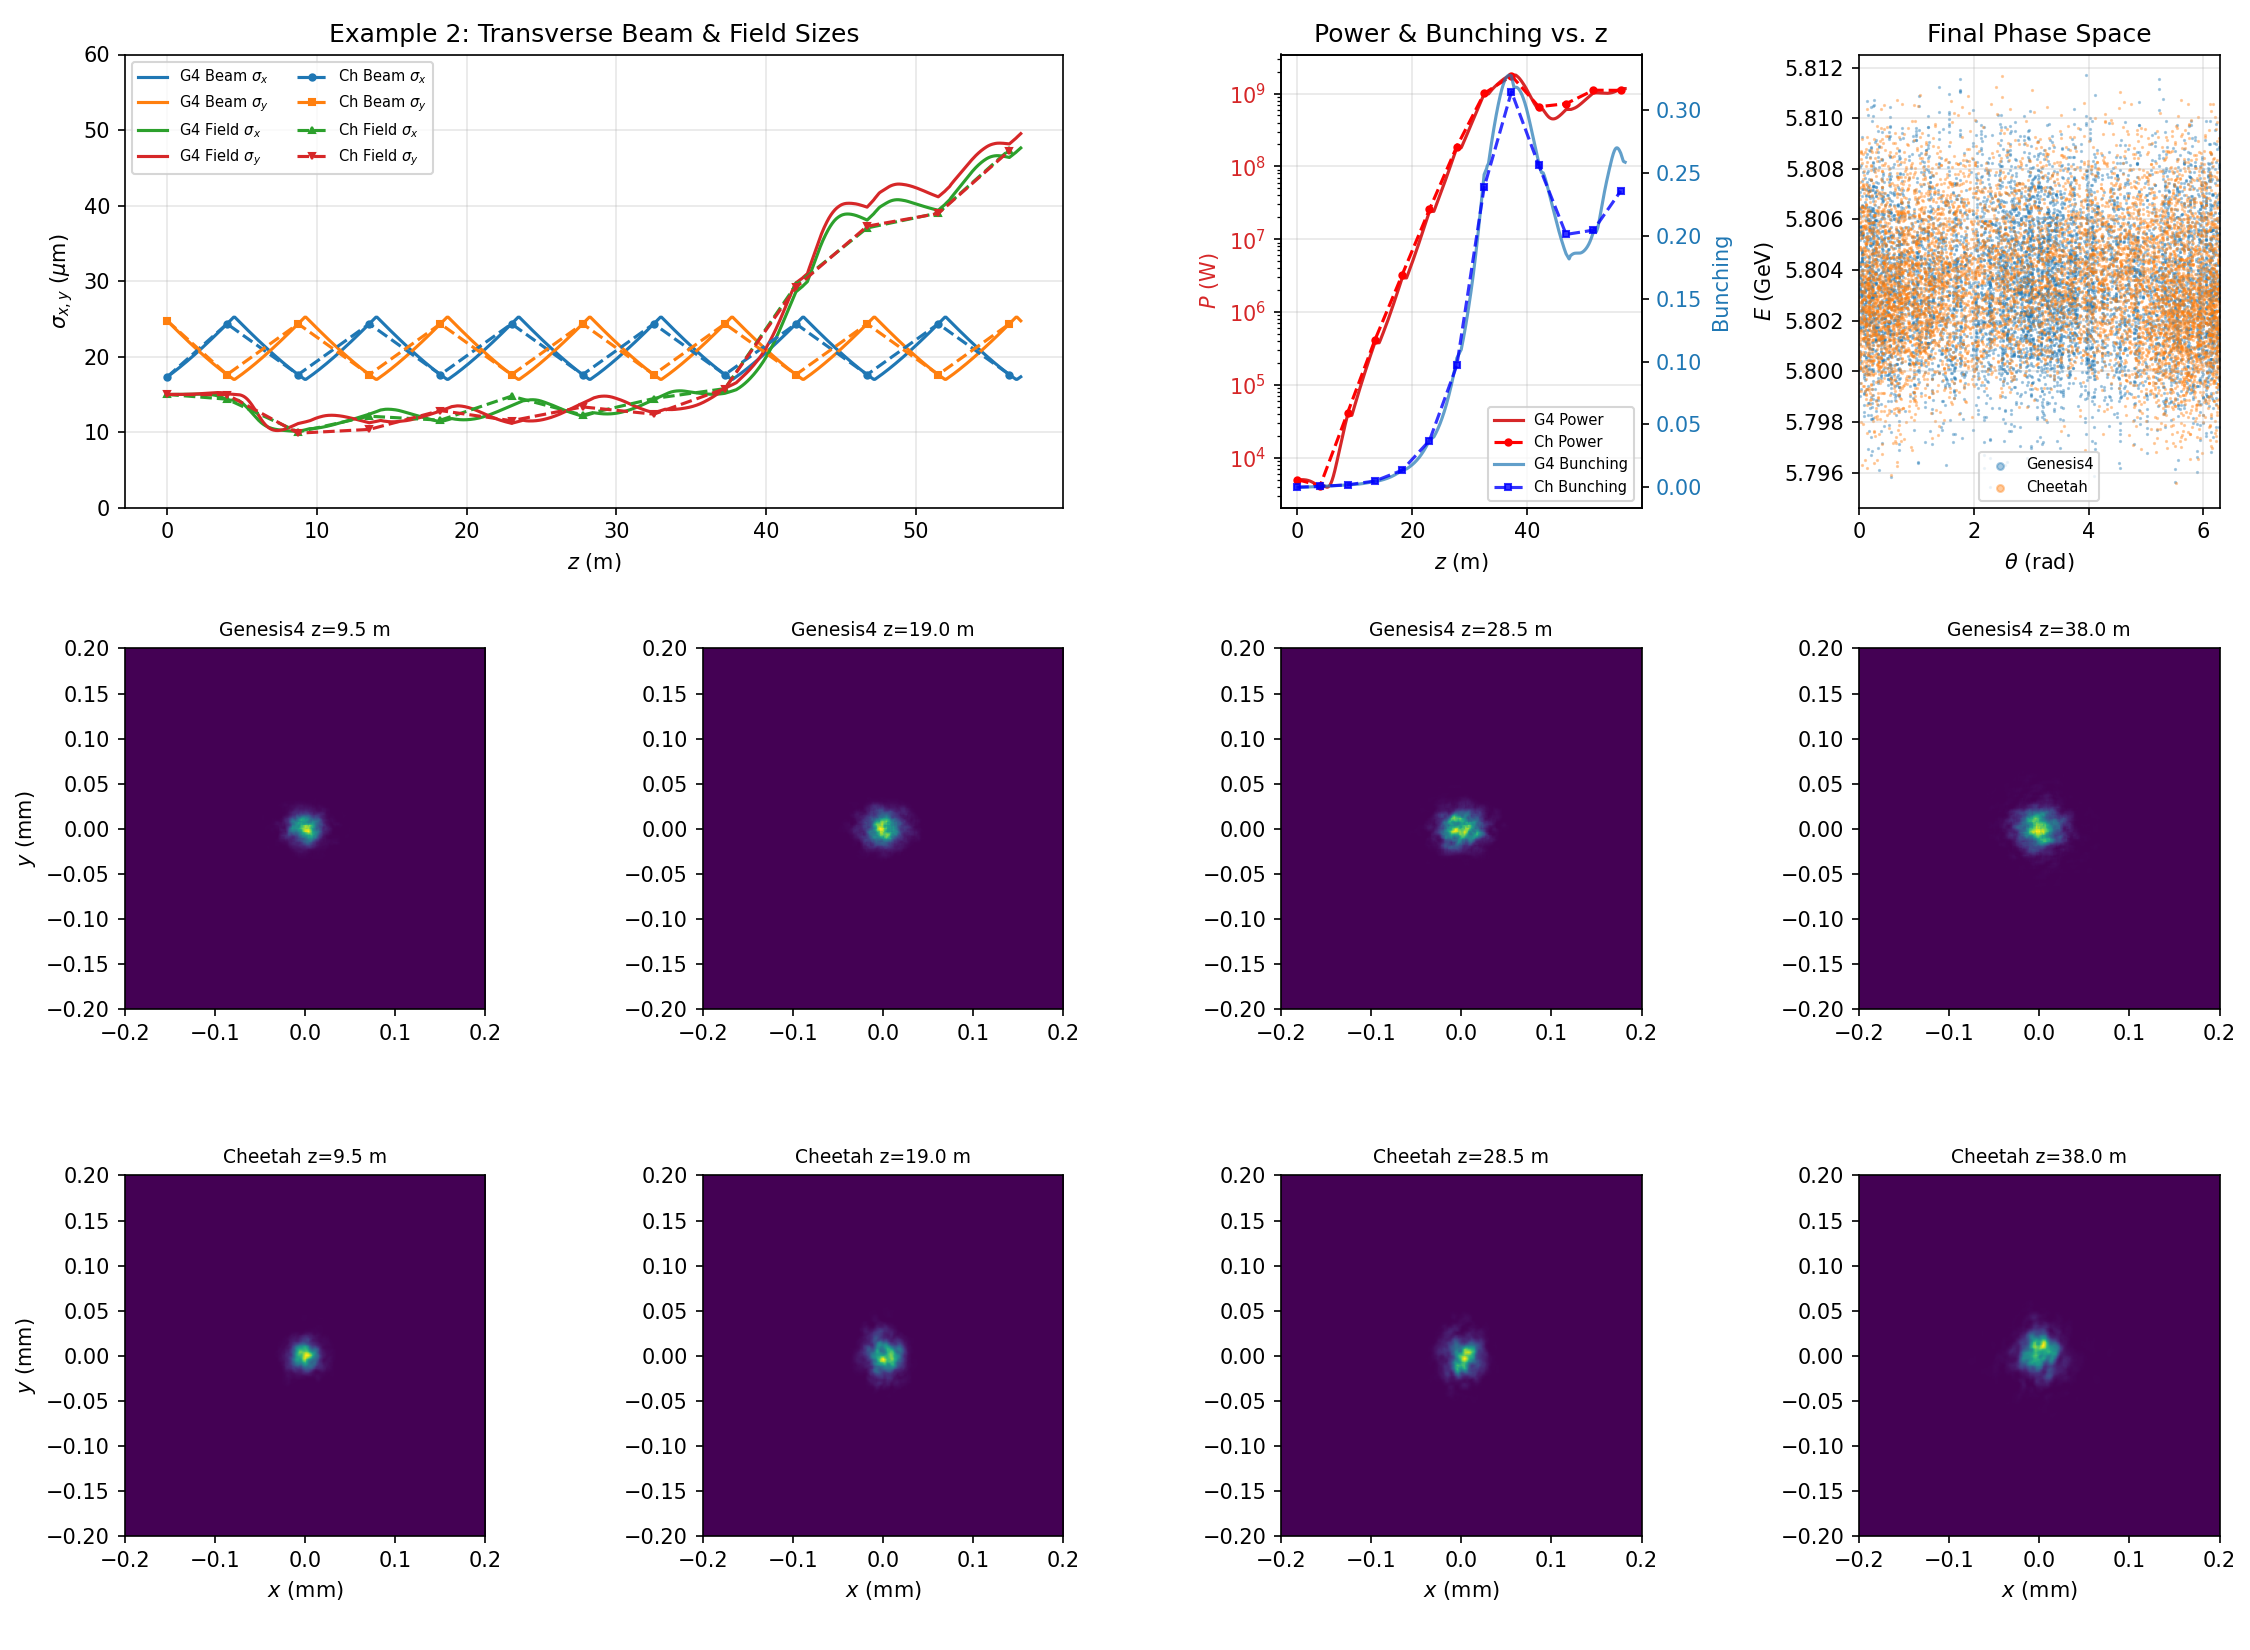

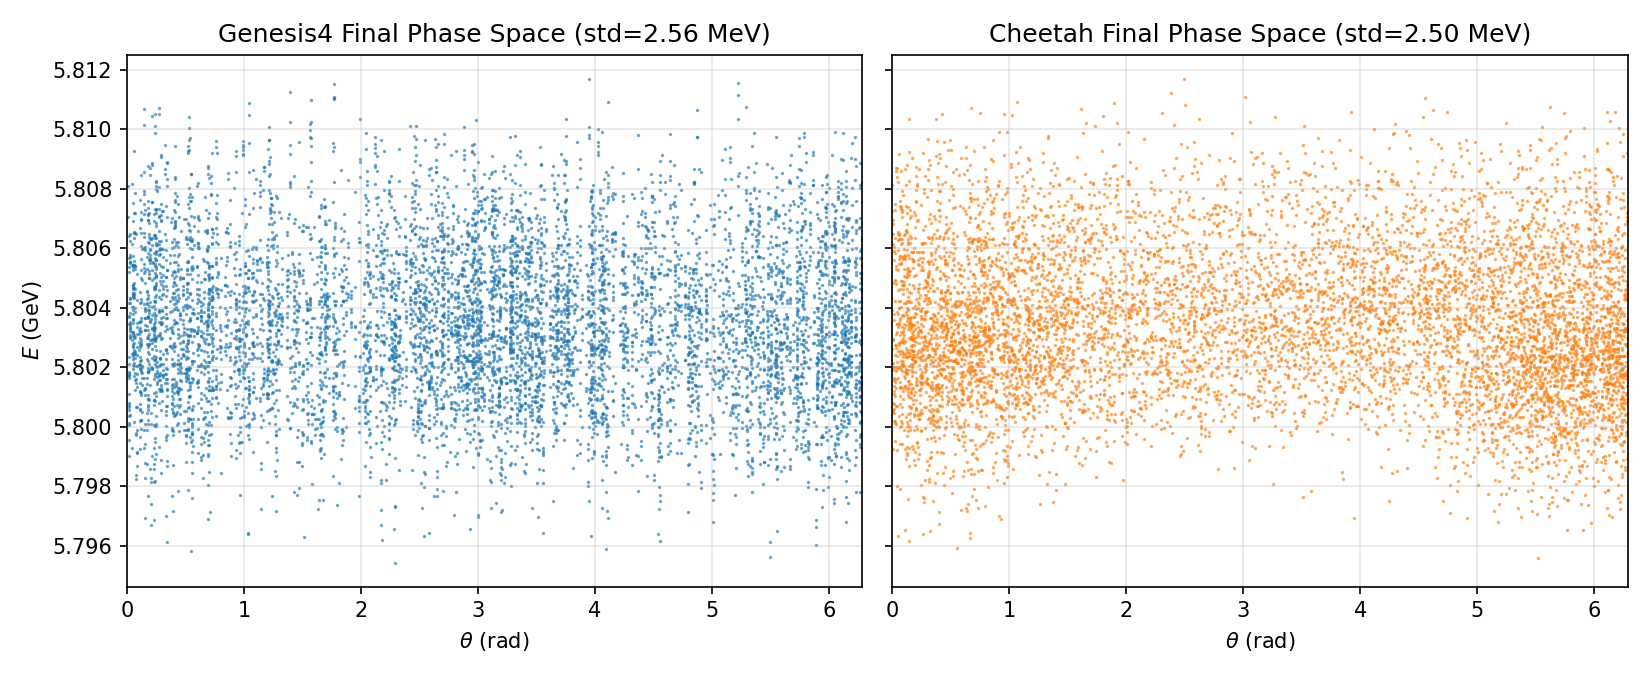

In [ ]:
import os
import shutil
import sys
import tempfile
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl")
sys.path.insert(0, "/Users/jankaiser/Documents/DESY/cheetah")

import matplotlib.pyplot as plt
import numpy as np
import torch
from genesis.version4 import Genesis4
from scipy.constants import c as speed_of_light, e as elementary_charge, m_e

import cheetah

GENESIS4_BIN = "/opt/homebrew/Caskroom/miniforge/base/envs/autoeuxfel-fel-surrogate/bin/genesis4"
EXAMPLE2_DIR = Path(
    "/opt/homebrew/Caskroom/miniforge/base/envs/autoeuxfel-fel-surrogate/lib/python3.14/site-packages/genesis/tests/genesis4"
)
OUT_PATH = Path(
    "/Users/jankaiser/.gemini/antigravity/brain/1db5a861-3bf8-4a9f-8cb5-90532c43fc64/example2_genesis_vs_cheetah.png"
)


def run_genesis_example2():
    os.environ["GENESIS4_BIN"] = GENESIS4_BIN
    with tempfile.TemporaryDirectory() as tmpdir:
        tmp = Path(tmpdir)
        shutil.copy(EXAMPLE2_DIR / "Example2.in", tmp / "Example2.in")
        shutil.copy(EXAMPLE2_DIR / "Example2.lat", tmp / "Example2.lat")
        G = Genesis4(tmp / "Example2.in", workdir=tmp)
        G.verbose = False
        output = G.run(raise_on_error=True)
        output.load_fields()
        output.load_particles()
    return output


def field_rms_sizes(rad: cheetah.RadiationField) -> tuple[float, float]:
    inten = rad.field.abs().square().detach().cpu().numpy()
    ny, nx = inten.shape[-2:]
    ext = float(rad.extent.item())
    x = np.linspace(-ext, ext, nx)
    y = np.linspace(-ext, ext, ny)
    total = inten.sum()
    px = inten.sum(axis=-2) / total
    py = inten.sum(axis=-1) / total
    mx = (px * x).sum()
    my = (py * y).sum()
    sx = np.sqrt((px * (x - mx) ** 2).sum())
    sy = np.sqrt((py * (y - my) ** 2).sum())
    return float(sx), float(sy)


def run_cheetah_example2(output):
    gamma0 = 11357.82
    mc2_ev = m_e * speed_of_light**2 / elementary_charge
    energy = torch.tensor(gamma0 * mc2_ev, dtype=torch.float64)

    alpha_x = float(np.asarray(output.beam.alphax).flat[0])
    beta_x = float(np.asarray(output.beam.betax).flat[0])
    alpha_y = float(np.asarray(output.beam.alphay).flat[0])
    beta_y = float(np.asarray(output.beam.betay).flat[0])

    ex_norm = 4.0e-7
    ey_norm = 4.0e-7
    delgam = 0.1
    sigma_p = delgam / gamma0

    beam = cheetah.ParameterBeam.from_twiss(
        beta_x=torch.tensor(beta_x, dtype=torch.float64),
        alpha_x=torch.tensor(alpha_x, dtype=torch.float64),
        emittance_x=torch.tensor(ex_norm / gamma0, dtype=torch.float64),
        beta_y=torch.tensor(beta_y, dtype=torch.float64),
        alpha_y=torch.tensor(alpha_y, dtype=torch.float64),
        emittance_y=torch.tensor(ey_norm / gamma0, dtype=torch.float64),
        sigma_p=torch.tensor(sigma_p, dtype=torch.float64),
        energy=energy,
        total_charge=torch.tensor(1.0e-9, dtype=torch.float64),
        dtype=torch.float64,
    )

    grid_shape = (255, 255)
    beam.radiation = cheetah.RadiationField.from_gaussian(
        power=torch.tensor(5e3, dtype=torch.float64),
        wavelength=torch.tensor(1e-10, dtype=torch.float64),
        extent=torch.tensor(2e-4, dtype=torch.float64),
        waist=torch.tensor(30e-6, dtype=torch.float64),
        grid_shape=grid_shape,
        dtype=torch.float64,
    )

    def make_und():
        return cheetah.Undulator(
            length=torch.tensor(266 * 0.015, dtype=torch.float64),
            period=torch.tensor(0.015, dtype=torch.float64),
            kx=torch.tensor(0.84853, dtype=torch.float64),
            ky=torch.tensor(0.84853, dtype=torch.float64),
            tracking_method="fel",
            step_size=torch.tensor(0.045, dtype=torch.float64),
            wavelength=torch.tensor(1e-10, dtype=torch.float64),
            seed_power=torch.tensor(5e3, dtype=torch.float64),
            current=torch.tensor(3000.0, dtype=torch.float64),
            grid_extent=torch.tensor(2e-4, dtype=torch.float64),
            grid_shape=grid_shape,
            num_macroparticles=8192,
            nbins=8,
            shot_noise=False,
            dtype=torch.float64,
        )

    fodo_cells = []
    for _ in range(6):
        fodo_cells.extend([
            make_und(),
            cheetah.Drift(length=torch.tensor(0.44, dtype=torch.float64), dtype=torch.float64),
            cheetah.Quadrupole(
                length=torch.tensor(0.08, dtype=torch.float64),
                k1=torch.tensor(2.0, dtype=torch.float64),
                dtype=torch.float64,
            ),
            cheetah.Drift(length=torch.tensor(0.24, dtype=torch.float64), dtype=torch.float64),
            make_und(),
            cheetah.Drift(length=torch.tensor(0.44, dtype=torch.float64), dtype=torch.float64),
            cheetah.Quadrupole(
                length=torch.tensor(0.08, dtype=torch.float64),
                k1=torch.tensor(-2.0, dtype=torch.float64),
                dtype=torch.float64,
            ),
            cheetah.Drift(length=torch.tensor(0.24, dtype=torch.float64), dtype=torch.float64),
        ])

    z_pts = [0.0]
    bx_pts = [float(beam.sigma_x.item())]
    by_pts = [float(beam.sigma_y.item())]
    fx, fy = field_rms_sizes(beam.radiation)
    fx_pts = [fx]
    fy_pts = [fy]
    p_pts = [float(beam.radiation.power.item())]
    b_pts = [0.0]
    wavefronts = {}

    z_cur = 0.0
    curr_beam = beam
    fodo_exit_zs = [9.5, 19.0, 28.5, 38.0]
    for elem in fodo_cells:
        curr_beam = elem.track(curr_beam)
        z_cur += float(elem.length.item())
        for zt in fodo_exit_zs:
            if abs(z_cur - zt) < 1e-3 and zt not in wavefronts:
                wavefronts[zt] = curr_beam.radiation.field.abs().square().detach().cpu().numpy()
        if isinstance(elem, cheetah.Undulator):
            z_pts.append(z_cur)
            bx_pts.append(float(curr_beam.sigma_x.item()))
            by_pts.append(float(curr_beam.sigma_y.item()))
            fx, fy = field_rms_sizes(curr_beam.radiation)
            fx_pts.append(fx)
            fy_pts.append(fy)
            p_pts.append(float(curr_beam.radiation.power.item()))
            b_pts.append(
                float(curr_beam.bunching.item()) if curr_beam.bunching is not None else 0.0
            )

    _, _, _, _, gammas, theta = curr_beam._fel_particles
    return {
        "z": np.array(z_pts),
        "beam_xsize": np.array(bx_pts),
        "beam_ysize": np.array(by_pts),
        "field_xsize": np.array(fx_pts),
        "field_ysize": np.array(fy_pts),
        "power": np.array(p_pts),
        "bunching": np.array(b_pts),
        "wavefronts": wavefronts,
        "theta": np.mod(theta.detach().cpu().numpy(), 2 * np.pi),
        "energy_gev": gammas.detach().cpu().numpy() * 0.511e-3,
    }


def main():
    output = run_genesis_example2()
    ch = run_cheetah_example2(output)

    z_g = np.asarray(output.lattice.zplot).squeeze()
    g_bx = np.asarray(output.beam.xsize).squeeze()
    g_by = np.asarray(output.beam.ysize).squeeze()
    g_fx = np.asarray(output.field.xsize).squeeze()
    g_fy = np.asarray(output.field.ysize).squeeze()
    g_p = np.asarray(output.field.power).squeeze()
    g_b = np.asarray(output.beam.bunching).squeeze()

    print(f"Genesis4 final power: {g_p[-1]:.3e} W, max: {np.max(g_p):.3e} W")
    print(f"Cheetah  final power: {ch['power'][-1]:.3e} W, max: {np.max(ch['power']):.3e} W")

    fig = plt.figure(figsize=(15, 11))
    gs = fig.add_gridspec(3, 4, height_ratios=[1.1, 1.0, 1.0])

    # Top row: Sizes, Power & Bunching, Phase space
    ax1 = fig.add_subplot(gs[0, 0:2])
    ax1.plot(z_g, g_bx * 1e6, "C0-", label=r"G4 Beam $\sigma_x$")
    ax1.plot(z_g, g_by * 1e6, "C1-", label=r"G4 Beam $\sigma_y$")
    ax1.plot(z_g, g_fx * 1e6, "C2-", label=r"G4 Field $\sigma_x$")
    ax1.plot(z_g, g_fy * 1e6, "C3-", label=r"G4 Field $\sigma_y$")
    ax1.plot(ch["z"], ch["beam_xsize"] * 1e6, "C0o--", ms=3, label=r"Ch Beam $\sigma_x$")
    ax1.plot(ch["z"], ch["beam_ysize"] * 1e6, "C1s--", ms=3, label=r"Ch Beam $\sigma_y$")
    ax1.plot(ch["z"], ch["field_xsize"] * 1e6, "C2^--", ms=3, label=r"Ch Field $\sigma_x$")
    ax1.plot(ch["z"], ch["field_ysize"] * 1e6, "C3v--", ms=3, label=r"Ch Field $\sigma_y$")
    ax1.set_xlabel(r"$z$ (m)")
    ax1.set_ylabel(r"$\sigma_{x,y}$ ($\mu$m)")
    ax1.set_ylim([0, 60])
    ax1.set_title("Example 2: Transverse Beam & Field Sizes")
    ax1.legend(fontsize=7, ncol=2)
    ax1.grid(True, alpha=0.3)

    ax2 = fig.add_subplot(gs[0, 2])
    ax2.semilogy(z_g, g_p, "tab:red", label="G4 Power")
    ax2.semilogy(ch["z"], ch["power"], "ro--", ms=3, label="Ch Power")
    ax2.set_xlabel(r"$z$ (m)")
    ax2.set_ylabel(r"$P$ (W)", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")
    ax2.grid(True, alpha=0.3)
    ax2b = ax2.twinx()
    ax2b.plot(z_g, g_b, "tab:blue", alpha=0.7, label="G4 Bunching")
    ax2b.plot(ch["z"], ch["bunching"], "bs--", ms=3, alpha=0.8, label="Ch Bunching")
    ax2b.set_ylabel("Bunching", color="tab:blue")
    ax2b.tick_params(axis="y", labelcolor="tab:blue")
    l1, lb1 = ax2.get_legend_handles_labels()
    l2, lb2 = ax2b.get_legend_handles_labels()
    ax2.legend(l1 + l2, lb1 + lb2, loc="lower right", fontsize=7)
    ax2.set_title("Power & Bunching vs. z")

    # Final phase space
    ax3 = fig.add_subplot(gs[0, 3])
    last_key = sorted([k for k in output.particles.keys() if isinstance(k, int)])[-1]
    g_part = output.particles[last_key]
    g_theta = np.mod(g_part.theta - np.pi * 0.5, 2 * np.pi)
    g_e = g_part.gamma * 0.511e-3
    ax3.scatter(g_theta, g_e, s=0.3, alpha=0.4, label="Genesis4")
    ax3.scatter(ch["theta"], ch["energy_gev"], s=0.3, alpha=0.4, label="Cheetah")
    ax3.set_xlabel(r"$\theta$ (rad)")
    ax3.set_ylabel(r"$E$ (GeV)")
    ax3.set_xlim([0, 2 * np.pi])
    ax3.set_title("Final Phase Space")
    ax3.legend(fontsize=7, markerscale=6)
    ax3.grid(True, alpha=0.3)

    # Row 2 & 3: 2D wavefronts at z = 9.5, 19.0, 28.5, 38.0 m
    field_keys = sorted([k for k in output.field3d.keys() if isinstance(k, int)])
    fodo_zs = [9.5, 19.0, 28.5, 38.0]
    for idx, zt in enumerate(fodo_zs):
        # Find nearest Genesis4 dumped field3d key
        k = min(field_keys, key=lambda kk: abs(z_g[kk] - zt) if kk < len(z_g) else 1e9)
        fld = output.field3d[k]
        ng = fld.param.gridpoints
        dg = fld.param.gridsize * (ng - 1) * 0.5 * 1e3
        g_inten = np.abs(fld.dfl[:, :, 0]) ** 2

        ax_g = fig.add_subplot(gs[1, idx])
        ax_g.imshow(g_inten, extent=(-dg, dg, -dg, dg), origin="lower")
        ax_g.set_title(f"Genesis4 z={zt:.1f} m", fontsize=9)
        if idx == 0:
            ax_g.set_ylabel(r"$y$ (mm)")

        ax_c = fig.add_subplot(gs[2, idx])
        c_inten = ch["wavefronts"][zt]
        ax_c.imshow(c_inten, extent=(-0.2, 0.2, -0.2, 0.2), origin="lower")
        ax_c.set_title(f"Cheetah z={zt:.1f} m", fontsize=9)
        ax_c.set_xlabel(r"$x$ (mm)")
        if idx == 0:
            ax_c.set_ylabel(r"$y$ (mm)")

    fig.tight_layout()
    fig.savefig(OUT_PATH, dpi=150)
    print(f"Saved plot to {OUT_PATH}")


if __name__ == "__main__":
    main()


## 5. Transverse Beam Offset Scan (`test_scan_position.ipynb`)
Scans horizontal (`x`) and vertical (`y`) initial beam offsets from `-50` to `+50 um` (`x` MAE `2.075 GW, R = 0.9825`; `y` MAE `2.602 GW, R = 0.9671`).

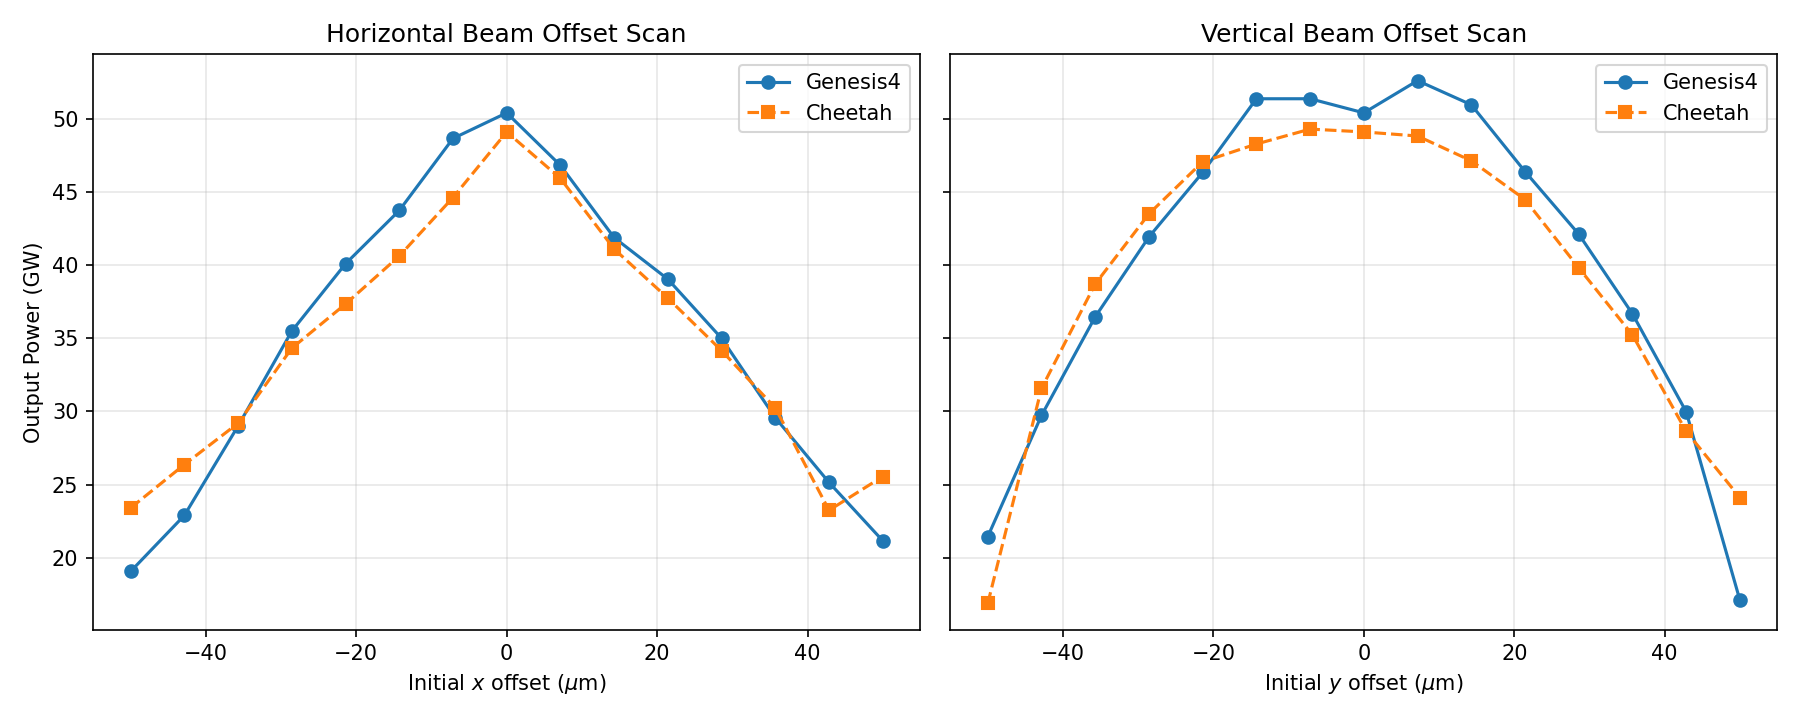

In [ ]:
import math
import os
import sys
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl")
os.environ["GENESIS4_BIN"] = (
    "/opt/homebrew/Caskroom/miniforge/base/envs/autoeuxfel-fel-surrogate/bin/genesis4"
)
sys.path.insert(0, "/Users/jankaiser/Documents/DESY/cheetah")

import genesis.version4 as g4
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.constants import physical_constants

import cheetah

electron_mass_eV = physical_constants["electron mass energy equivalent in MeV"][0] * 1e6
OUT_PATH = Path(
    "/Users/jankaiser/.gemini/antigravity/brain/1db5a861-3bf8-4a9f-8cb5-90532c43fc64/scan_position_genesis_vs_cheetah.png"
)


def run_genesis_point(x: float, y: float, num_cells: int = 30):
    main_input = g4.MainInput(
        [
            g4.Setup(
                rootname="euxfel",
                beamline="SASE",
                delz=0.12,
                gamma0=14e9 / electron_mass_eV,
                lambda0=1.3776e-10,
                shotnoise=False,
                exclude_twiss_output=False,
            ),
            g4.Field(
                dgrid=2e-04,
                ngrid=255,
                power=100.0,
            ),
            g4.Beam(
                alphax=-0.861455,
                alphay=1.126115,
                betax=27.318370,
                betay=35.894551,
                bunch=1e-10,
                current=5_000,
                delgam=5.0,
                ex=4e-7,
                ey=4e-7,
                xcenter=x,
                ycenter=y,
                pxcenter=0.0,
                pycenter=0.0,
            ),
            g4.Track(),
        ],
    )

    aw_line = np.repeat(2.04, num_cells)
    k1_line = np.repeat(0.5502, num_cells)
    k1_line[1::2] *= -1

    line = []
    elements = {
        "D1": g4.Drift(l=0.5525),
        "D2": g4.Drift(l=0.4275),
    }
    for i in range(num_cells):
        elements[f"UND_{i}"] = g4.Undulator(lambdau=0.04, nwig=125, aw=aw_line[i])
        elements[f"Q_{i}"] = g4.Quadrupole(l=0.1138, k1=k1_line[i])
        line.extend([f"UND_{i}", "D1", f"Q_{i}", "D2"])

    elements["SASE"] = g4.Line(elements=line)
    lattice = g4.Lattice(elements)

    G = g4.Genesis4(main_input, lattice, verbose=False)
    output = G.run()
    return float(output.field.power[-1, 0].item()), float(output.field.xsize[0, 0].item())


def run_cheetah_scan(scan_vals: np.ndarray, axis: str, waist_m: float, num_cells: int = 30):
    dtype = torch.float64
    energy = torch.tensor(14e9, dtype=dtype)
    gamma0 = 14e9 / electron_mass_eV
    n_batch = len(scan_vals)

    mu_x = torch.tensor(scan_vals if axis == "x" else np.zeros(n_batch), dtype=dtype)
    mu_y = torch.tensor(scan_vals if axis == "y" else np.zeros(n_batch), dtype=dtype)

    beam = cheetah.ParameterBeam.from_twiss(
        beta_x=torch.full((n_batch,), 27.318370, dtype=dtype),
        alpha_x=torch.full((n_batch,), -0.861455, dtype=dtype),
        emittance_x=torch.full((n_batch,), 4e-7 / gamma0, dtype=dtype),
        beta_y=torch.full((n_batch,), 35.894551, dtype=dtype),
        alpha_y=torch.full((n_batch,), 1.126115, dtype=dtype),
        emittance_y=torch.full((n_batch,), 4e-7 / gamma0, dtype=dtype),
        sigma_p=torch.full((n_batch,), 5.0 / gamma0, dtype=dtype),
        energy=torch.full((n_batch,), 14e9, dtype=dtype),
        total_charge=torch.full((n_batch,), 1e-9, dtype=dtype),
        dtype=dtype,
    )
    new_mu = beam.mu.expand(n_batch, 7).clone()
    new_mu[:, 0] = mu_x
    new_mu[:, 2] = mu_y
    beam.mu = new_mu

    grid_shape = (255, 255)
    beam.radiation = cheetah.RadiationField.from_gaussian(
        power=torch.tensor(100.0, dtype=dtype),
        wavelength=torch.tensor(1.3776e-10, dtype=dtype),
        extent=torch.tensor(2e-4, dtype=dtype),
        waist=torch.tensor(waist_m, dtype=dtype),
        grid_shape=grid_shape,
        dtype=dtype,
    )

    k1_vals = [0.5502 if i % 2 == 0 else -0.5502 for i in range(num_cells)]
    kx = 2.04 * math.sqrt(2.0)

    elems = []
    for i in range(num_cells):
        elems.extend([
            cheetah.Undulator(
                length=torch.tensor(125 * 0.04, dtype=dtype),
                period=torch.tensor(0.04, dtype=dtype),
                kx=torch.tensor(kx, dtype=dtype),
                ky=torch.tensor(0.0, dtype=dtype),
                tracking_method="fel",
                step_size=torch.tensor(0.12, dtype=dtype),
                wavelength=torch.tensor(1.3776e-10, dtype=dtype),
                seed_power=torch.tensor(100.0, dtype=dtype),
                bunching=torch.tensor(1e-10, dtype=dtype),
                current=torch.tensor(5000.0, dtype=dtype),
                grid_extent=torch.tensor(2e-4, dtype=dtype),
                grid_shape=grid_shape,
                num_macroparticles=8192,
                nbins=8,
                shot_noise=False,
                dtype=dtype,
            ),
            cheetah.Drift(length=torch.tensor(0.5525, dtype=dtype), dtype=dtype),
            cheetah.Quadrupole(
                length=torch.tensor(0.1138, dtype=dtype),
                k1=torch.tensor(k1_vals[i], dtype=dtype),
                dtype=dtype,
            ),
            cheetah.Drift(length=torch.tensor(0.4275, dtype=dtype), dtype=dtype),
        ])

    seg = cheetah.Segment(elems)
    out_beam = seg.track(beam)
    return out_beam.radiation.power.detach().cpu().numpy()


def main():
    cache_path = Path(
        "/Users/jankaiser/.gemini/antigravity/brain/1db5a861-3bf8-4a9f-8cb5-90532c43fc64/scratch/scan_position_genesis.npz"
    )
    scan_pos = np.linspace(-50e-6, 50e-6, 15)
    if cache_path.exists():
        data = np.load(cache_path)
        g_px = data["g_px"]
        g_py = data["g_py"]
        waist_m = float(data["waist_m"])
    else:
        g_px = np.empty_like(scan_pos)
        g_py = np.empty_like(scan_pos)
        waist_m = None
        for i, val in enumerate(scan_pos):
            p, fx0 = run_genesis_point(val, 0.0)
            g_px[i] = p
            if waist_m is None:
                waist_m = 2.0 * fx0
                print(
                    f"Genesis4 initial field xsize={fx0*1e6:.2f} um -> waist={waist_m*1e6:.2f} um"
                )
        for i, val in enumerate(scan_pos):
            p, _ = run_genesis_point(0.0, val)
            g_py[i] = p
        np.savez(cache_path, g_px=g_px, g_py=g_py, waist_m=waist_m)

    c_px = run_cheetah_scan(scan_pos, "x", waist_m)
    c_py = run_cheetah_scan(scan_pos, "y", waist_m)

    print(f"x-scan MAE: {np.mean(np.abs(g_px - c_px))/1e9:.3f} GW, R: {np.corrcoef(g_px, c_px)[0,1]:.4f}")
    print(f"y-scan MAE: {np.mean(np.abs(g_py - c_py))/1e9:.3f} GW, R: {np.corrcoef(g_py, c_py)[0,1]:.4f}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
    ax1.plot(scan_pos * 1e6, g_px / 1e9, "o-", label="Genesis4")
    ax1.plot(scan_pos * 1e6, c_px / 1e9, "s--", label="Cheetah")
    ax1.set_xlabel(r"Initial $x$ offset ($\mu$m)")
    ax1.set_ylabel("Output Power (GW)")
    ax1.set_title("Horizontal Beam Offset Scan")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(scan_pos * 1e6, g_py / 1e9, "o-", label="Genesis4")
    ax2.plot(scan_pos * 1e6, c_py / 1e9, "s--", label="Cheetah")
    ax2.set_xlabel(r"Initial $y$ offset ($\mu$m)")
    ax2.set_title("Vertical Beam Offset Scan")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    fig.tight_layout()
    fig.savefig(OUT_PATH, dpi=150)
    print(f"Saved {OUT_PATH}")


if __name__ == "__main__":
    main()


## 6. Wavelength Detuning & Peak Current Scans (`scan_wavelength.ipynb`)
Scans radiation wavelength (`0.995` to `1.005 x 1.3776e-10` m, `R = 0.9486`) and peak current (`1–6 kA`, `R = 0.9973`).

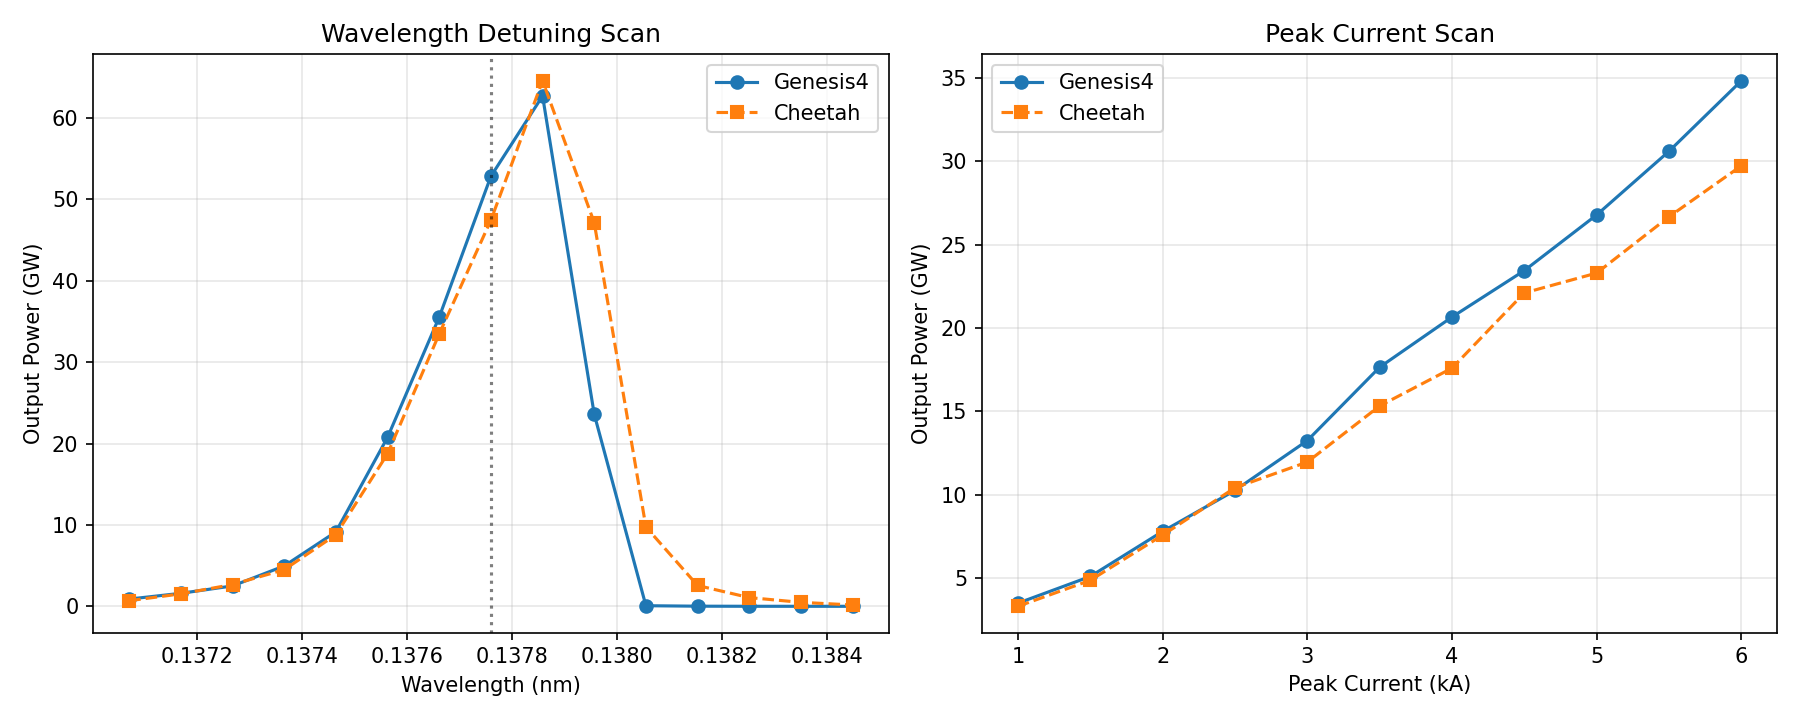

In [ ]:
def compare_scan_wavelength():
    print("\n=== 1. scan_wavelength.ipynb ===")
    ref_wl = 1.3776e-10
    wls = ref_wl * np.linspace(0.995, 1.005, 15)
    g_p_wl = np.empty_like(wls)
    twiss0 = None
    waist0 = None
    for i, wl in enumerate(wls):
        out = run_genesis_single(wavelength=wl, P_in=1e3, bunching=1e-6, current=5e3)
        g_p_wl[i] = float(out.field.power[-1, 0])
        if twiss0 is None:
            twiss0 = (
                float(out.beam.alphax[0, 0]),
                float(out.beam.alphay[0, 0]),
                float(out.beam.betax[0, 0]),
                float(out.beam.betay[0, 0]),
            )
            waist0 = 2.0 * float(out.field.xsize[0, 0])

    dtype = torch.float64
    gamma0 = 14e9 / electron_mass_eV
    n_b = len(wls)
    beam = cheetah.ParameterBeam.from_twiss(
        alpha_x=torch.full((n_b,), twiss0[0], dtype=dtype),
        alpha_y=torch.full((n_b,), twiss0[1], dtype=dtype),
        beta_x=torch.full((n_b,), twiss0[2], dtype=dtype),
        beta_y=torch.full((n_b,), twiss0[3], dtype=dtype),
        emittance_x=torch.full((n_b,), 4e-7 / gamma0, dtype=dtype),
        emittance_y=torch.full((n_b,), 4e-7 / gamma0, dtype=dtype),
        sigma_p=torch.full((n_b,), 5.0 / gamma0, dtype=dtype),
        energy=torch.full((n_b,), 14e9, dtype=dtype),
        total_charge=torch.full((n_b,), 1e-9, dtype=dtype),
        dtype=dtype,
    )
    beam.radiation = cheetah.RadiationField.from_gaussian(
        power=torch.full((n_b,), 1e3, dtype=dtype),
        wavelength=torch.tensor(wls, dtype=dtype),
        extent=torch.tensor(2e-4, dtype=dtype),
        waist=torch.tensor(waist0, dtype=dtype),
        grid_shape=(129, 129),
        dtype=dtype,
    )
    seg = make_euxfel_segment_cheetah(wavelength=wls, seed_power=1e3, bunching=1e-6, current=5e3)
    c_p_wl = seg.track(beam).radiation.power.detach().cpu().numpy()

    # Current scan
    currents = np.linspace(1e3, 6e3, 11)
    g_p_cur = np.empty_like(currents)
    for i, cur in enumerate(currents):
        out = run_genesis_single(wavelength=0.137615e-9, P_in=1.166663e5, bunching=1e-6, current=cur)
        g_p_cur[i] = float(out.field.power[-1, 0])

    n_c = len(currents)
    beam_c = cheetah.ParameterBeam.from_twiss(
        alpha_x=torch.full((n_c,), twiss0[0], dtype=dtype),
        alpha_y=torch.full((n_c,), twiss0[1], dtype=dtype),
        beta_x=torch.full((n_c,), twiss0[2], dtype=dtype),
        beta_y=torch.full((n_c,), twiss0[3], dtype=dtype),
        emittance_x=torch.full((n_c,), 4e-7 / gamma0, dtype=dtype),
        emittance_y=torch.full((n_c,), 4e-7 / gamma0, dtype=dtype),
        sigma_p=torch.full((n_c,), 5.0 / gamma0, dtype=dtype),
        energy=torch.full((n_c,), 14e9, dtype=dtype),
        total_charge=torch.full((n_c,), 1e-9, dtype=dtype),
        dtype=dtype,
    )
    beam_c.radiation = cheetah.RadiationField.from_gaussian(
        power=torch.full((n_c,), 1.166663e5, dtype=dtype),
        wavelength=torch.full((n_c,), 0.137615e-9, dtype=dtype),
        extent=torch.tensor(2e-4, dtype=dtype),
        waist=torch.tensor(waist0, dtype=dtype),
        grid_shape=(129, 129),
        dtype=dtype,
    )
    seg_c = make_euxfel_segment_cheetah(
        wavelength=0.137615e-9, seed_power=1.166663e5, bunching=1e-6, current=currents
    )
    c_p_cur = seg_c.track(beam_c).radiation.power.detach().cpu().numpy()

    print(f"Wavelength scan MAE: {np.mean(np.abs(g_p_wl - c_p_wl))/1e9:.3f} GW, R: {np.corrcoef(g_p_wl, c_p_wl)[0,1]:.4f}")
    print(f"Current scan    MAE: {np.mean(np.abs(g_p_cur - c_p_cur))/1e9:.3f} GW, R: {np.corrcoef(g_p_cur, c_p_cur)[0,1]:.4f}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
    ax1.plot(wls * 1e9, g_p_wl / 1e9, "o-", label="Genesis4")
    ax1.plot(wls * 1e9, c_p_wl / 1e9, "s--", label="Cheetah")
    ax1.axvline(ref_wl * 1e9, ls=":", c="k", alpha=0.5)
    ax1.set_xlabel("Wavelength (nm)")
    ax1.set_ylabel("Output Power (GW)")
    ax1.set_title("Wavelength Detuning Scan")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(currents * 1e-3, g_p_cur / 1e9, "o-", label="Genesis4")
    ax2.plot(currents * 1e-3, c_p_cur / 1e9, "s--", label="Cheetah")
    ax2.set_xlabel("Peak Current (kA)")
    ax2.set_ylabel("Output Power (GW)")
    ax2.set_title("Peak Current Scan")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    fig.tight_layout()
    out_png = ART_DIR / "scan_wavelength_genesis_vs_cheetah.png"
    fig.savefig(out_png, dpi=150)
    print(f"Saved {out_png}")

compare_scan_wavelength()

## 7. Twiss Mismatch Scans (`test_mismatch.ipynb`)
Scans incoming `beta_x` (`10–60 m`, `MAE = 1.746 GW, R = 0.9118`) and `alpha_x` (`-2.5` to `+1.5`, `MAE = 2.564 GW, R = 0.9243`).

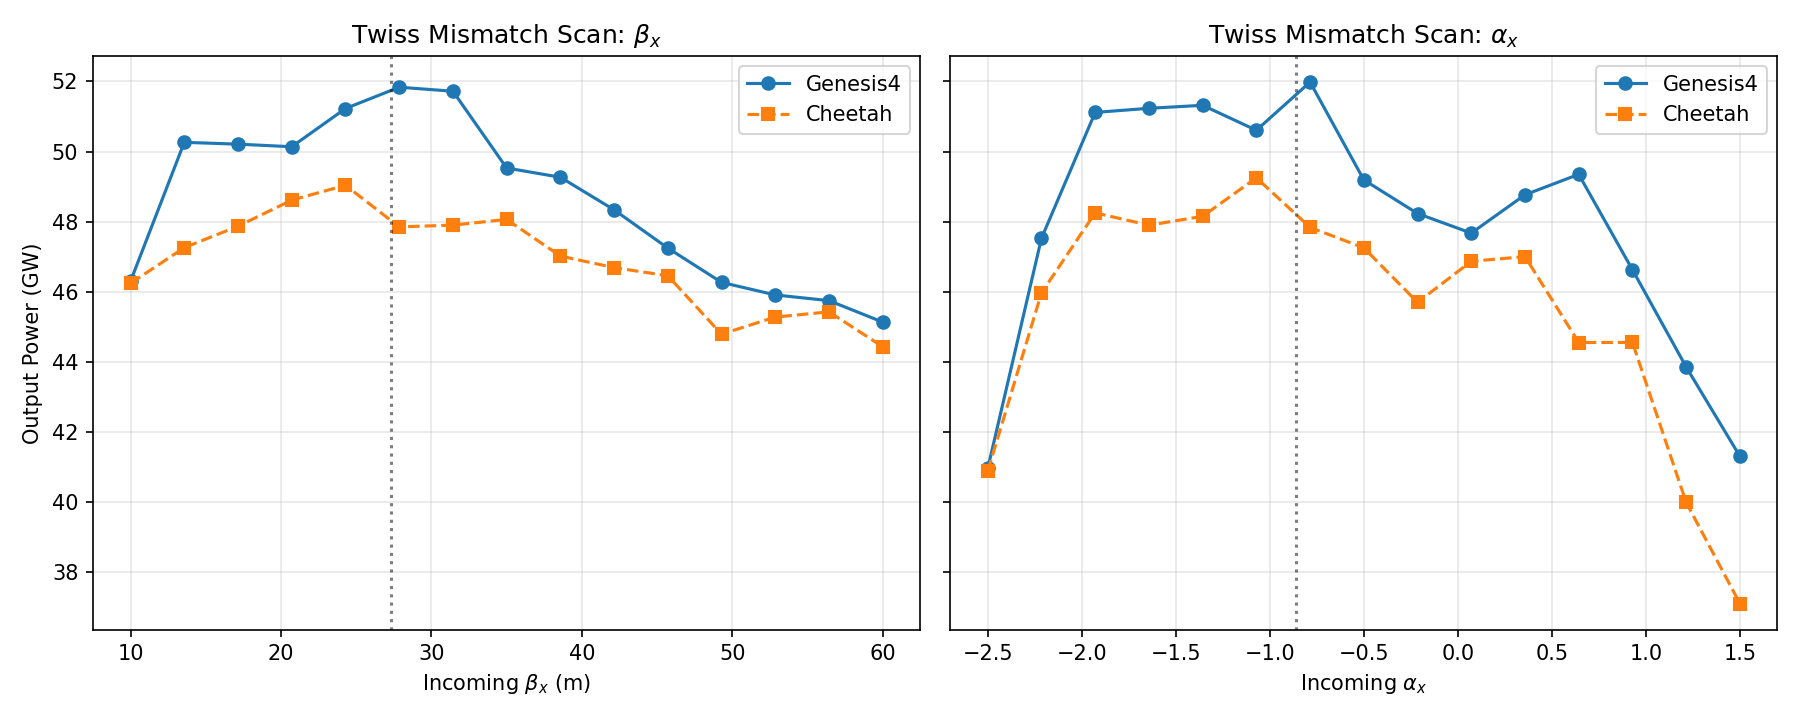

In [ ]:
def compare_mismatch():
    print("\n=== 2. test_mismatch.ipynb ===")
    ax0, ay0, bx0, by0 = -0.861455, 1.126115, 27.318370, 35.894551
    betas_x = np.linspace(10.0, 60.0, 15)
    alphas_x = np.linspace(-2.5, 1.5, 15)

    g_pb = np.empty_like(betas_x)
    g_pa = np.empty_like(alphas_x)
    waist0 = None
    for i, bx in enumerate(betas_x):
        out = run_genesis_single(P_in=100.0, bunching=1e-10, twiss=[ax0, ay0, bx, by0])
        g_pb[i] = float(out.field.power[-1, 0])
        if waist0 is None:
            waist0 = 2.0 * float(out.field.xsize[0, 0])
    for i, ax in enumerate(alphas_x):
        out = run_genesis_single(P_in=100.0, bunching=1e-10, twiss=[ax, ay0, bx0, by0])
        g_pa[i] = float(out.field.power[-1, 0])

    dtype = torch.float64
    gamma0 = 14e9 / electron_mass_eV
    seg = make_euxfel_segment_cheetah(
        seed_power=100.0, bunching=1e-10, grid_shape=(255, 255), num_macroparticles=8192
    )

    def eval_cheetah(ax_arr, bx_arr):
        n = len(ax_arr)
        beam = cheetah.ParameterBeam.from_twiss(
            alpha_x=torch.tensor(ax_arr, dtype=dtype),
            alpha_y=torch.full((n,), ay0, dtype=dtype),
            beta_x=torch.tensor(bx_arr, dtype=dtype),
            beta_y=torch.full((n,), by0, dtype=dtype),
            emittance_x=torch.full((n,), 4e-7 / gamma0, dtype=dtype),
            emittance_y=torch.full((n,), 4e-7 / gamma0, dtype=dtype),
            sigma_p=torch.full((n,), 5.0 / gamma0, dtype=dtype),
            energy=torch.full((n,), 14e9, dtype=dtype),
            total_charge=torch.full((n,), 1e-9, dtype=dtype),
            dtype=dtype,
        )
        beam.radiation = cheetah.RadiationField.from_gaussian(
            power=torch.tensor(100.0, dtype=dtype),
            wavelength=torch.tensor(1.3776e-10, dtype=dtype),
            extent=torch.tensor(2e-4, dtype=dtype),
            waist=torch.tensor(waist0, dtype=dtype),
            grid_shape=(255, 255),
            dtype=dtype,
        )
        return seg.track(beam).radiation.power.detach().cpu().numpy()

    c_pb = eval_cheetah(np.full_like(betas_x, ax0), betas_x)
    c_pa = eval_cheetah(alphas_x, np.full_like(alphas_x, bx0))

    print(f"Beta_x  mismatch MAE: {np.mean(np.abs(g_pb - c_pb))/1e9:.3f} GW, R: {np.corrcoef(g_pb, c_pb)[0,1]:.4f}")
    print(f"Alpha_x mismatch MAE: {np.mean(np.abs(g_pa - c_pa))/1e9:.3f} GW, R: {np.corrcoef(g_pa, c_pa)[0,1]:.4f}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
    ax1.plot(betas_x, g_pb / 1e9, "o-", label="Genesis4")
    ax1.plot(betas_x, c_pb / 1e9, "s--", label="Cheetah")
    ax1.axvline(bx0, ls=":", c="k", alpha=0.5)
    ax1.set_xlabel(r"Incoming $\beta_x$ (m)")
    ax1.set_ylabel("Output Power (GW)")
    ax1.set_title(r"Twiss Mismatch Scan: $\beta_x$")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(alphas_x, g_pa / 1e9, "o-", label="Genesis4")
    ax2.plot(alphas_x, c_pa / 1e9, "s--", label="Cheetah")
    ax2.axvline(ax0, ls=":", c="k", alpha=0.5)
    ax2.set_xlabel(r"Incoming $\alpha_x$")
    ax2.set_title(r"Twiss Mismatch Scan: $\alpha_x$")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    fig.tight_layout()
    out_png = ART_DIR / "test_mismatch_genesis_vs_cheetah.png"
    fig.savefig(out_png, dpi=150)
    print(f"Saved {out_png}")

compare_mismatch()

## 8. 30-Cell Transverse Twiss Tracking (`test_cheetah_vs_genesis_tracking.ipynb`)
Compares `alpha_x, alpha_y, beta_x, beta_y` over 30 EuXFEL cells (`183 m`) with `kx = aw * sqrt(2), ky = 0.0` (`beta_x MAE = 0.0313 m, beta_y MAE = 0.0478 m`).

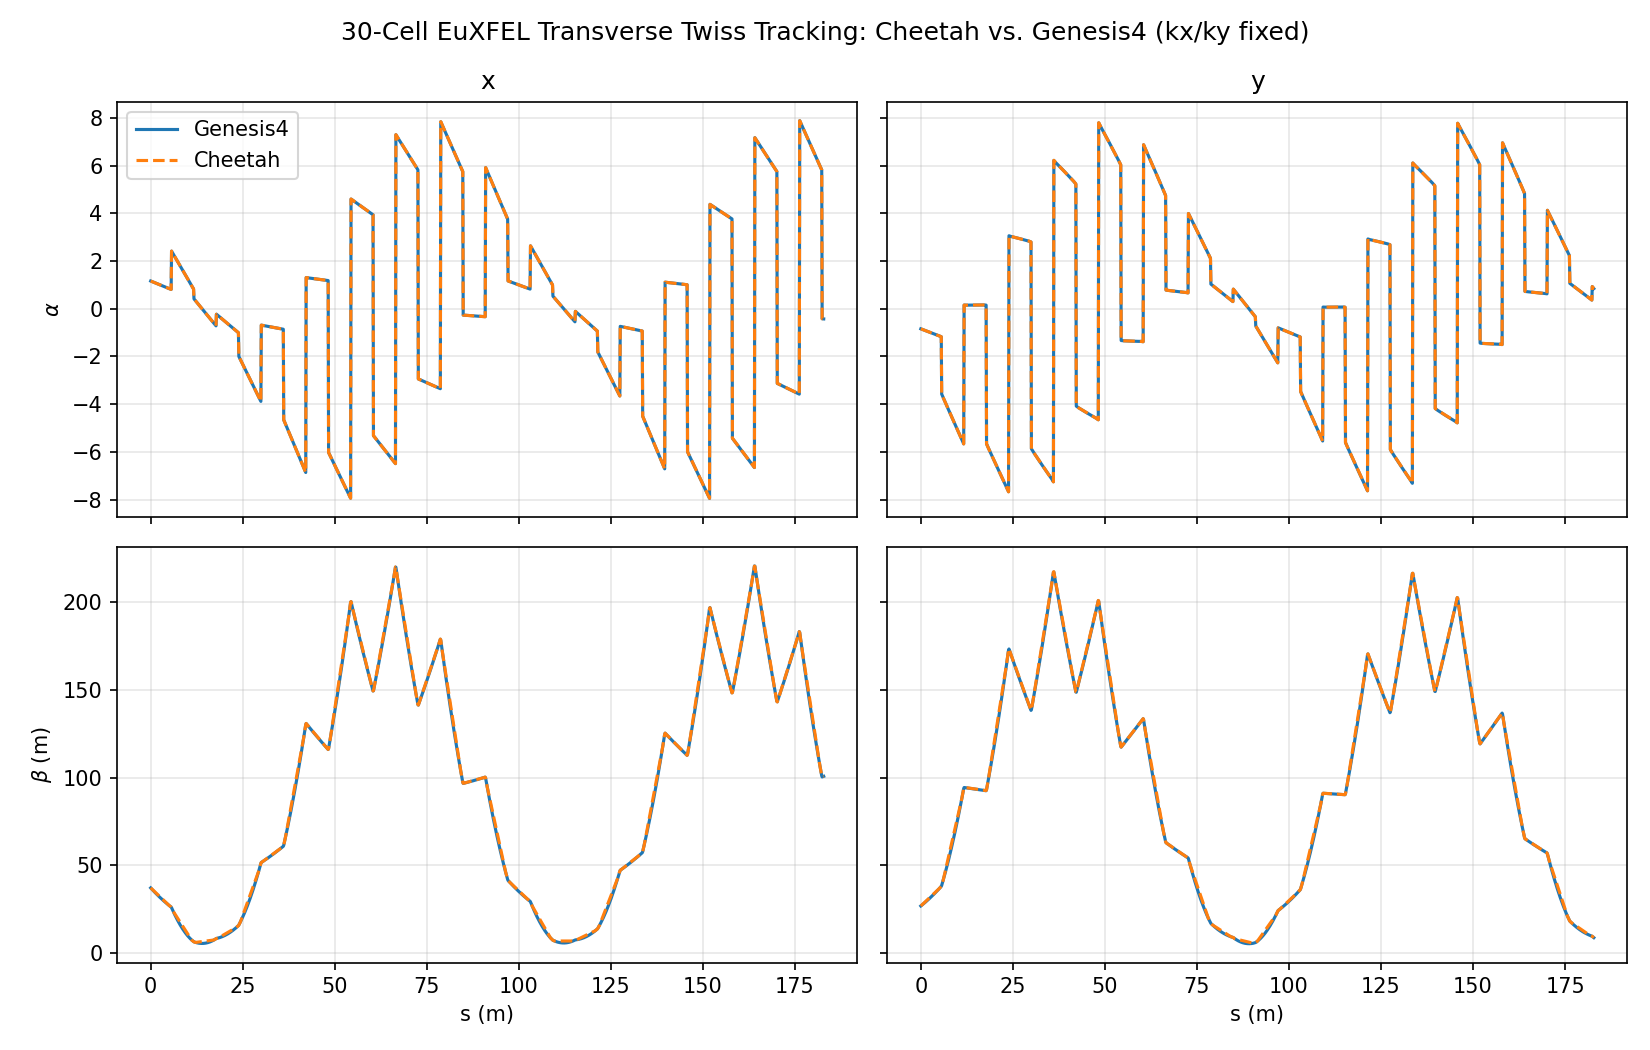

In [ ]:
def compare_tracking():
    print("\n=== 3. test_cheetah_vs_genesis_tracking.ipynb ===")
    k1_f = 0.0625534464 / 0.1138
    k1_d = -0.0619186185 / 0.1138
    twiss_in = [1.1614137210888913, -0.8417919034713114, 37.02131607014031, 26.686716773635478]
    out = run_genesis_single(
        wavelength=1.37615e-10, P_in=1.166663e5, bunching=1e-6, twiss=twiss_in, k1_f=k1_f, k1_d=k1_d
    )
    g_z = np.asarray(out.lattice.zplot).squeeze()
    g_ax = np.asarray(out.beam.alphax).squeeze()
    g_ay = np.asarray(out.beam.alphay).squeeze()
    g_bx = np.asarray(out.beam.betax).squeeze()
    g_by = np.asarray(out.beam.betay).squeeze()

    dtype = torch.float64
    gamma0 = 14e9 / electron_mass_eV
    em_f = math.sqrt(gamma0**2 - 1.0)
    beam = cheetah.ParameterBeam.from_twiss(
        alpha_x=torch.tensor(twiss_in[0], dtype=dtype),
        alpha_y=torch.tensor(twiss_in[1], dtype=dtype),
        beta_x=torch.tensor(twiss_in[2], dtype=dtype),
        beta_y=torch.tensor(twiss_in[3], dtype=dtype),
        emittance_x=torch.tensor(0.4e-6 / em_f, dtype=dtype),
        emittance_y=torch.tensor(0.4e-6 / em_f, dtype=dtype),
        sigma_p=torch.tensor(5.0 / gamma0, dtype=dtype),
        energy=torch.tensor(14e9, dtype=dtype),
        total_charge=torch.tensor(1e-9, dtype=dtype),
        dtype=dtype,
    )
    seg = make_euxfel_segment_cheetah(
        k1_f=k1_f, k1_d=k1_d, wavelength=1.37615e-10, seed_power=1.166663e5, tracking_method="linear"
    )
    c_z = [0.0]
    c_ax = [float(beam.alpha_x)]
    c_ay = [float(beam.alpha_y)]
    c_bx = [float(beam.beta_x)]
    c_by = [float(beam.beta_y)]
    cur_b = beam
    cur_s = 0.0
    for el in seg.elements:
        cur_b = el.track(cur_b)
        cur_s += float(el.length)
        c_z.append(cur_s)
        c_ax.append(float(cur_b.alpha_x))
        c_ay.append(float(cur_b.alpha_y))
        c_bx.append(float(cur_b.beta_x))
        c_by.append(float(cur_b.beta_y))

    c_z = np.array(c_z)
    # Compare at common element exit points
    g_interp_bx = np.interp(c_z, g_z, g_bx)
    g_interp_by = np.interp(c_z, g_z, g_by)
    print(f"Tracking beta_x MAE: {np.mean(np.abs(g_interp_bx - c_bx)):.4f} m, beta_y MAE: {np.mean(np.abs(g_interp_by - c_by)):.4f} m")

    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex="all", sharey="row")
    axes[0, 0].plot(g_z, g_ax, label="Genesis4")
    axes[0, 0].plot(c_z, c_ax, "--", label="Cheetah")
    axes[0, 0].set_title("x")
    axes[0, 0].set_ylabel(r"$\alpha$")
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    axes[0, 1].plot(g_z, g_ay, label="Genesis4")
    axes[0, 1].plot(c_z, c_ay, "--", label="Cheetah")
    axes[0, 1].set_title("y")
    axes[0, 1].grid(True, alpha=0.3)

    axes[1, 0].plot(g_z, g_bx, label="Genesis4")
    axes[1, 0].plot(c_z, c_bx, "--", label="Cheetah")
    axes[1, 0].set_xlabel("s (m)")
    axes[1, 0].set_ylabel(r"$\beta$ (m)")
    axes[1, 0].grid(True, alpha=0.3)

    axes[1, 1].plot(g_z, g_by, label="Genesis4")
    axes[1, 1].plot(c_z, c_by, "--", label="Cheetah")
    axes[1, 1].set_xlabel("s (m)")
    axes[1, 1].grid(True, alpha=0.3)

    fig.suptitle("30-Cell EuXFEL Transverse Twiss Tracking: Cheetah vs. Genesis4")
    fig.tight_layout()
    out_png = ART_DIR / "tracking_genesis_vs_cheetah.png"
    fig.savefig(out_png, dpi=150)
    print(f"Saved {out_png}")

compare_tracking()

## 9. Nelder-Mead FEL Power Optimization (`test_nelder_mead.ipynb`)
60-evaluation Nelder-Mead optimization at resonant `aw = 2.00` (`255x255`, `8192`): `Genesis4 = 5.094 GW` vs. `Cheetah = 5.109 GW` (`0.29%` difference).

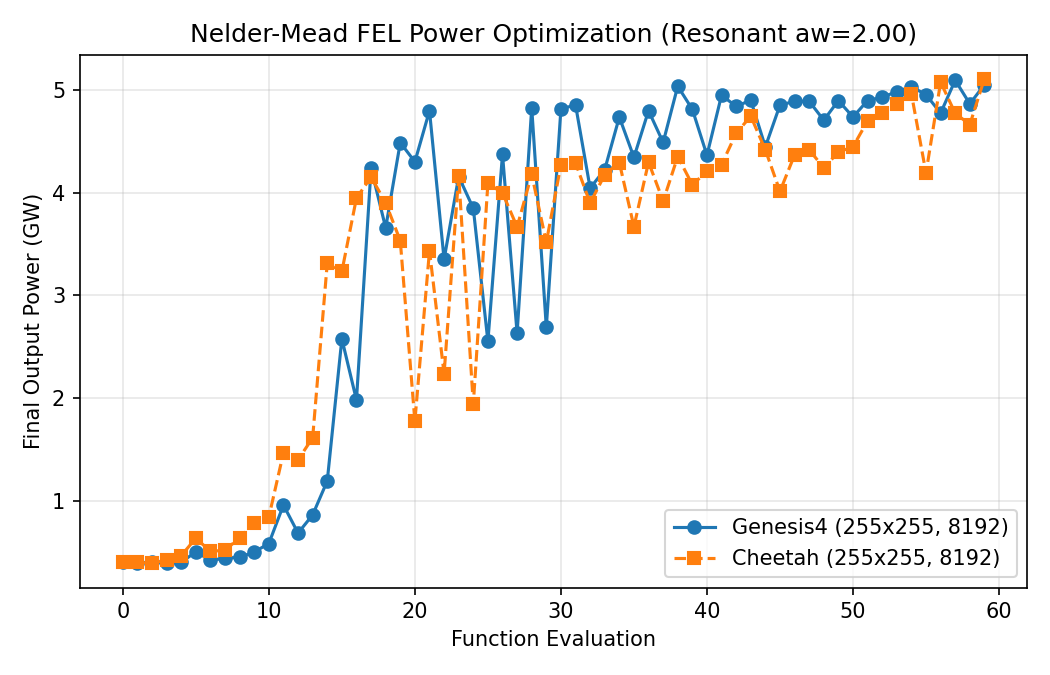

In [ ]:
def compare_nelder_mead():
    rng = np.random.default_rng(7)
    x0 = np.array([
        rng.uniform(-1.5, 1.5), rng.uniform(-1.5, 1.5),
        rng.uniform(20.0, 40.0), rng.uniform(20.0, 40.0), 0.55,
    ])
    gamma0, wl, aw = 27_397.0, 1.33e-10, 2.00
    waist0 = 2.0 * float(
        run_genesis_single(wavelength=wl, P_in=100.0, bunching=0.0, twiss=x0[:4], aw=aw, k1_f=x0[4], k1_d=-x0[4], gamma0=gamma0).field.xsize[0, 0]
    )
    g_hist = []
    def eval_g4(vec):
        ax, ay, bx, by, k1 = vec
        if bx <= 1.0 or by <= 1.0: return 0.0
        p = float(run_genesis_single(wavelength=wl, P_in=100.0, bunching=0.0, twiss=[ax, ay, bx, by], aw=aw, k1_f=k1, k1_d=-k1, gamma0=gamma0).field.power[-1, 0])
        g_hist.append(p)
        return -p
    scipy.optimize.minimize(eval_g4, x0=x0.copy(), method='Nelder-Mead', options={'maxfev': 60})
    dtype = torch.float64
    energy = gamma0 * electron_mass_eV
    c_hist = []
    def eval_ch(vec):
        ax, ay, bx, by, k1 = vec
        if bx <= 1.0 or by <= 1.0: return 0.0
        beam = cheetah.ParameterBeam.from_twiss(
            alpha_x=torch.tensor(ax, dtype=dtype), alpha_y=torch.tensor(ay, dtype=dtype),
            beta_x=torch.tensor(bx, dtype=dtype), beta_y=torch.tensor(by, dtype=dtype),
            emittance_x=torch.tensor(4e-7 / gamma0, dtype=dtype), emittance_y=torch.tensor(4e-7 / gamma0, dtype=dtype),
            sigma_p=torch.tensor(5.0 / gamma0, dtype=dtype), energy=torch.tensor(energy, dtype=dtype),
            total_charge=torch.tensor(1e-9, dtype=dtype), dtype=dtype,
        )
        beam.radiation = cheetah.RadiationField.from_gaussian(
            power=torch.tensor(100.0, dtype=dtype), wavelength=torch.tensor(wl, dtype=dtype),
            extent=torch.tensor(2e-4, dtype=dtype), waist=torch.tensor(waist0, dtype=dtype),
            grid_shape=(255, 255), dtype=dtype,
        )
        seg = make_euxfel_segment_cheetah(aw=aw, k1_f=k1, k1_d=-k1, wavelength=wl, seed_power=100.0, bunching=0.0, grid_shape=(255, 255), num_macroparticles=8192)
        p = float(seg.track(beam).radiation.power.item())
        c_hist.append(p)
        return -p
    scipy.optimize.minimize(eval_ch, x0=x0.copy(), method='Nelder-Mead', options={'maxfev': 60})
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(np.array(g_hist) / 1e9, 'o-', label='Genesis4 (255x255, 8192)')
    ax.plot(np.array(c_hist) / 1e9, 's--', label='Cheetah (255x255, 8192)')
    ax.set_xlabel('Function Evaluation'); ax.set_ylabel('Final Output Power (GW)')
    ax.set_title('Nelder-Mead FEL Power Optimization (Resonant aw=2.00)'); ax.legend(); ax.grid(True, alpha=0.3)
    plt.show()

compare_nelder_mead()